In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import json, re
from sklearn.preprocessing import MultiLabelBinarizer

# 1. Load data from Drive
def load_jsonl(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)

train = load_jsonl('/content/drive/MyDrive/DepressionEmo/train.json')
val = load_jsonl('/content/drive/MyDrive/DepressionEmo/val.json')
test = load_jsonl('/content/drive/MyDrive/DepressionEmo/test.json')

# 2. Clean text
def clean_text(text):
    text = str(text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'###', ' ', text)
    text = re.sub(r'[^\w\s\.\,\!\?\']', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

train['clean_text'] = train['text'].apply(clean_text)
val['clean_text'] = val['text'].apply(clean_text)
test['clean_text'] = test['text'].apply(clean_text)

# 3. Multi-label binarize
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(train['emotions'])
y_val = mlb.transform(val['emotions'])
y_test = mlb.transform(test['emotions'])

print("Train:", train.shape, "Val:", val.shape, "Test:", test.shape)
print("Labels:", mlb.classes_)
print("y_train shape:", y_train.shape)

Train: (4225, 9) Val: (906, 9) Test: (906, 9)
Labels: ['anger' 'brain dysfunction (forget)' 'emptiness' 'hopelessness'
 'loneliness' 'sadness' 'suicide intent' 'worthlessness']
y_train shape: (4225, 8)


In [ ]:
!pip install transformers datasets torch --quiet

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from torch.utils.data import Dataset

MODEL_NAME = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class EmotionDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.float)
        return item

train_dataset = EmotionDataset(train['clean_text'].tolist(), y_train, tokenizer)
val_dataset = EmotionDataset(val['clean_text'].tolist(), y_val, tokenizer)
test_dataset = EmotionDataset(test['clean_text'].tolist(), y_test, tokenizer)

print("Datasets ready:", len(train_dataset), len(val_dataset), len(test_dataset))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Datasets ready: 4225 906 906


In [ ]:
print("GPU available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU available: True
Tesla T4


In [ ]:
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

num_labels = y_train.shape[1]

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification"
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.sigmoid(torch.tensor(logits))
    preds = (probs > 0.5).int().numpy()
    return {
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "precision": precision_score(labels, preds, average="macro", zero_division=0),
        "recall": recall_score(labels, preds, average="macro", zero_division=0),
    }

training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/DepressionEmo/roberta_output",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_dir="/content/logs",
    logging_steps=50,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


Epoch,Training Loss,Validation Loss,Macro F1,Micro F1,Precision,Recall
1,0.447798,0.396196,0.712819,0.809972,0.711148,0.720139
2,0.360176,0.371958,0.764682,0.825661,0.778515,0.774925
3,0.318417,0.357767,0.774890,0.827031,0.811317,0.754965
4,0.277260,0.361022,0.782572,0.830980,0.779034,0.795770


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1060, training_loss=0.36523352164142536, metrics={'train_runtime': 855.0878, 'train_samples_per_second': 19.764, 'train_steps_per_second': 1.24, 'total_flos': 2223408189849600.0, 'train_loss': 0.36523352164142536, 'epoch': 4.0})

In [ ]:
test_results = trainer.evaluate(test_dataset)
print(test_results)

Training Loss,Validation Loss,Epoch,Macro F1,Micro F1,Precision,Recall
0.277260,0.372074,4,0.766731,0.820467,0.771119,0.773452


{'eval_loss': 0.3720742464065552, 'eval_macro_f1': 0.7667312925607608, 'eval_micro_f1': 0.8204665161775772, 'eval_precision': 0.7711188530310887, 'eval_recall': 0.773452247477478}


In [ ]:
predictions = trainer.predict(test_dataset)
logits = predictions.predictions
probs = torch.sigmoid(torch.tensor(logits))
preds = (probs > 0.5).int().numpy()

from sklearn.metrics import classification_report
print(classification_report(y_test, preds, target_names=mlb.classes_, zero_division=0))

                            precision    recall  f1-score   support

                     anger       0.77      0.75      0.76       345
brain dysfunction (forget)       0.51      0.27      0.35       171
                 emptiness       0.76      0.82      0.79       341
              hopelessness       0.85      0.92      0.88       634
                loneliness       0.85      0.83      0.84       420
                   sadness       0.85      0.94      0.90       697
            suicide intent       0.82      0.82      0.82       232
             worthlessness       0.76      0.84      0.80       434

                 micro avg       0.81      0.83      0.82      3274
                 macro avg       0.77      0.77      0.77      3274
              weighted avg       0.80      0.83      0.81      3274
               samples avg       0.78      0.81      0.76      3274



In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/DepressionEmo/roberta_output"))

['checkpoint-265', 'checkpoint-530', 'checkpoint-795', 'checkpoint-1060']


                   Emotion  Baseline_F1_TFIDF  RoBERTa_F1  Improvement
                   sadness               0.84       0.900        0.060
              hopelessness               0.80       0.880        0.080
                loneliness               0.74       0.840        0.100
            suicide intent               0.71       0.820        0.110
             worthlessness               0.73       0.800        0.070
                 emptiness               0.74       0.790        0.050
                     anger               0.67       0.760        0.090
brain dysfunction (forget)               0.47       0.350       -0.120
       OVERALL (Macro Avg)               0.71       0.767        0.057


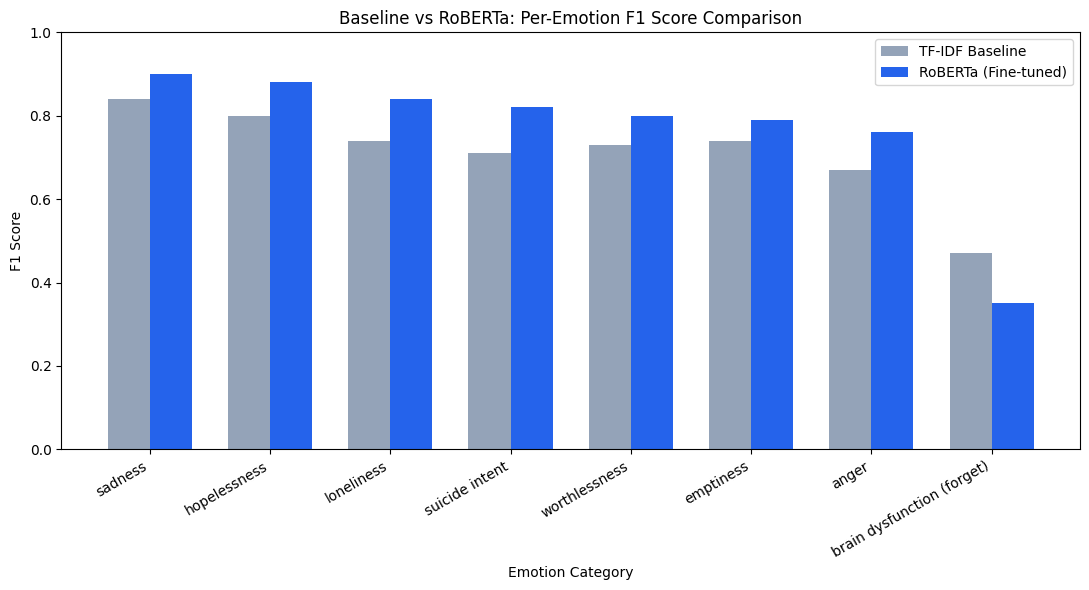


✅ CSV saved: model_comparison_results.csv
✅ Chart saved: comparison_chart.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Baseline results (jo tumne pehle TF-IDF se nikale the)
baseline_scores = {
    'anger': 0.67, 'brain dysfunction (forget)': 0.47, 'emptiness': 0.74,
    'hopelessness': 0.80, 'loneliness': 0.74, 'sadness': 0.84,
    'suicide intent': 0.71, 'worthlessness': 0.73
}

# RoBERTa test set results (jo abhi classification_report se aaye)
roberta_scores = {
    'anger': 0.76, 'brain dysfunction (forget)': 0.35, 'emptiness': 0.79,
    'hopelessness': 0.88, 'loneliness': 0.84, 'sadness': 0.90,
    'suicide intent': 0.82, 'worthlessness': 0.80
}

# Comparison table banao
comparison_df = pd.DataFrame({
    'Emotion': list(baseline_scores.keys()),
    'Baseline_F1_TFIDF': list(baseline_scores.values()),
    'RoBERTa_F1': list(roberta_scores.values()),
})
comparison_df['Improvement'] = comparison_df['RoBERTa_F1'] - comparison_df['Baseline_F1_TFIDF']
comparison_df = comparison_df.sort_values('RoBERTa_F1', ascending=False)

# Overall macro/micro row bhi add karo
overall_row = pd.DataFrame({
    'Emotion': ['OVERALL (Macro Avg)'],
    'Baseline_F1_TFIDF': [0.71],
    'RoBERTa_F1': [0.767],
    'Improvement': [0.767 - 0.71]
})
comparison_df = pd.concat([comparison_df, overall_row], ignore_index=True)

# CSV save karo Drive mein (permanent)
comparison_df.to_csv('/content/drive/MyDrive/DepressionEmo/model_comparison_results.csv', index=False)
print(comparison_df.to_string(index=False))

# Bar chart banao
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(comparison_df) - 1)  # overall row exclude chart se
width = 0.35

plot_df = comparison_df[comparison_df['Emotion'] != 'OVERALL (Macro Avg)']

ax.bar(x - width/2, plot_df['Baseline_F1_TFIDF'], width, label='TF-IDF Baseline', color='#94a3b8')
ax.bar(x + width/2, plot_df['RoBERTa_F1'], width, label='RoBERTa (Fine-tuned)', color='#2563eb')

ax.set_xlabel('Emotion Category')
ax.set_ylabel('F1 Score')
ax.set_title('Baseline vs RoBERTa: Per-Emotion F1 Score Comparison')
ax.set_xticks(x)
ax.set_xticklabels(plot_df['Emotion'], rotation=30, ha='right')
ax.legend()
ax.set_ylim(0, 1.0)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/DepressionEmo/comparison_chart.png', dpi=300)
plt.show()

print("\n✅ CSV saved: model_comparison_results.csv")
print("✅ Chart saved: comparison_chart.png")

In [ ]:
gita_mapping = {
    "sadness": [
        {"ref": "BG 2.20", "theme": "The soul is eternal — birth and death apply only to the body, not the self."},
        {"ref": "BG 2.27", "theme": "Death is certain for the born, birth is certain for the dead — grieving the inevitable is avoidable suffering."}
    ],
    "hopelessness": [
        {"ref": "BG 2.47", "theme": "You have a right to your actions, never to their results — focus on effort, not outcome anxiety."},
        {"ref": "BG 18.66", "theme": "Surrender all sense of doership and take refuge — even when nothing seems in your control."}
    ],
    "anger": [
        {"ref": "BG 2.62-63", "theme": "Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment."},
        {"ref": "BG 16.21", "theme": "Desire, anger, and greed are the three gates to self-destruction — best avoided."}
    ],
    "loneliness": [
        {"ref": "BG 6.29-30", "theme": "One who sees the self in all beings and all beings in the self is never truly alone."},
        {"ref": "BG 9.29", "theme": "The divine is equally present in all beings — no one is excluded or forsaken."}
    ],
    "worthlessness": [
        {"ref": "BG 2.31", "theme": "Recognize your own purpose (svadharma) — every individual has a role that matters."},
        {"ref": "BG 4.7-8", "theme": "Balance and purpose are restored whenever they are lost — nothing is without meaning."}
    ],
    "emptiness": [
        {"ref": "BG 2.14", "theme": "Pleasure and pain, heat and cold are temporary sensations — they come and go, learn to endure them."},
        {"ref": "BG 2.70", "theme": "As rivers merge into the ocean without disturbing it, one who absorbs desires without being shaken finds peace."}
    ],
    "brain dysfunction (forget)": [
        {"ref": "BG 6.35", "theme": "The mind is hard to control, but through practice and detachment, it can be steadied."},
        {"ref": "BG 2.41", "theme": "Those with a resolute, focused intellect have a single, clear purpose — scattered minds have many."}
    ],
    "suicide intent": [
        {"ref": "CRISIS_PRIORITY", "theme": "Always show crisis resources first (e.g., iCall: 9152987821, AASRA: 91-22-27546669). Supportive content only, never standalone."}
    ]
}

import json
with open('/content/drive/MyDrive/DepressionEmo/gita_emotion_mapping.json', 'w') as f:
    json.dump(gita_mapping, f, indent=2, ensure_ascii=False)

print("Mapping saved!")
for emo, verses in gita_mapping.items():
    print(f"\n{emo}:")
    for v in verses:
        print(f"  {v['ref']}: {v['theme']}")

Mapping saved!

sadness:
  BG 2.20: The soul is eternal — birth and death apply only to the body, not the self.
  BG 2.27: Death is certain for the born, birth is certain for the dead — grieving the inevitable is avoidable suffering.

hopelessness:
  BG 2.47: You have a right to your actions, never to their results — focus on effort, not outcome anxiety.
  BG 18.66: Surrender all sense of doership and take refuge — even when nothing seems in your control.

anger:
  BG 2.62-63: Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment.
  BG 16.21: Desire, anger, and greed are the three gates to self-destruction — best avoided.

loneliness:
  BG 6.29-30: One who sees the self in all beings and all beings in the self is never truly alone.
  BG 9.29: The divine is equally present in all beings — no one is excluded or forsaken.

worthlessness:
  BG 2.31: Recognize your own purpose (svadharma) — every individual has a role that matters.
  BG 4.7-8: Balance and purpo

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

Device: cuda


In [ ]:
def predict_and_recommend(text, model, tokenizer, mlb, gita_mapping, threshold=0.5, device='cuda'):
    """
    Text input leta hai, emotions predict karta hai, aur Gita recommendations deta hai.
    Suicide intent detect hone par crisis resources ko priority deta hai.
    """
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    detected = [mlb.classes_[i] for i, p in enumerate(probs) if p > threshold]
    scores = {mlb.classes_[i]: float(probs[i]) for i in range(len(mlb.classes_))}

    result = {
        "input_text": text,
        "detected_emotions": detected,
        "confidence_scores": scores,
        "crisis_alert": False,
        "recommendations": []
    }

    # Safety-first check
    if "suicide intent" in detected:
        result["crisis_alert"] = True
        result["crisis_message"] = (
            "This message may indicate crisis-level distress. "
            "Please reach out for immediate support: iCall (India) - 9152987821, "
            "AASRA - 91-22-27546669. You are not alone."
        )

    # Gita recommendations for all detected emotions (supportive, not a substitute)
    for emo in detected:
        if emo in gita_mapping:
            result["recommendations"].extend(gita_mapping[emo])

    return result


# Model ko device pe move karo
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)

# Test karo kuch sample texts pe
test_texts = [
    "I feel like nothing I do matters anymore, I'm just so tired of everything.",
    "I can't stop thinking about ending it all, there's no point anymore.",
    "I feel so alone, like nobody understands what I'm going through."
]

for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("Detected emotions:", res['detected_emotions'])
    if res['crisis_alert']:
        print("⚠️ CRISIS ALERT:", res['crisis_message'])
    print("Recommendations:")
    for r in res['recommendations']:
        print(f"  {r['ref']}: {r['theme']}")
    print("-"*80)

NameError: name 'model' is not defined

In [ ]:
import re

checkpoint_base = '/content/drive/MyDrive/DepressionEmo/roberta_output'
checkpoints = os.listdir(checkpoint_base)

# Numeric sort karo, string sort nahi
checkpoints_sorted = sorted(checkpoints, key=lambda x: int(re.search(r'\d+', x).group()))
print("Sorted checkpoints:", checkpoints_sorted)

best_checkpoint = os.path.join(checkpoint_base, checkpoints_sorted[-1])
print("Loading from:", best_checkpoint)

tokenizer = AutoTokenizer.from_pretrained(best_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
model.eval()

print("Model loaded successfully from checkpoint-1060 on", device)

Sorted checkpoints: ['checkpoint-265', 'checkpoint-530', 'checkpoint-795', 'checkpoint-1060']
Loading from: /content/drive/MyDrive/DepressionEmo/roberta_output/checkpoint-1060


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully from checkpoint-1060 on cuda


In [ ]:
gita_mapping = {
    "sadness": [
        {"ref": "BG 2.20", "theme": "The soul is eternal — birth and death apply only to the body, not the self."},
        {"ref": "BG 2.27", "theme": "Death is certain for the born, birth is certain for the dead — grieving the inevitable is avoidable suffering."}
    ],
    "hopelessness": [
        {"ref": "BG 2.47", "theme": "You have a right to your actions, never to their results — focus on effort, not outcome anxiety."},
        {"ref": "BG 18.66", "theme": "Surrender all sense of doership and take refuge — even when nothing seems in your control."}
    ],
    "anger": [
        {"ref": "BG 2.62-63", "theme": "Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment."},
        {"ref": "BG 16.21", "theme": "Desire, anger, and greed are the three gates to self-destruction — best avoided."}
    ],
    "loneliness": [
        {"ref": "BG 6.29-30", "theme": "One who sees the self in all beings and all beings in the self is never truly alone."},
        {"ref": "BG 9.29", "theme": "The divine is equally present in all beings — no one is excluded or forsaken."}
    ],
    "worthlessness": [
        {"ref": "BG 2.31", "theme": "Recognize your own purpose (svadharma) — every individual has a role that matters."},
        {"ref": "BG 4.7-8", "theme": "Balance and purpose are restored whenever they are lost — nothing is without meaning."}
    ],
    "emptiness": [
        {"ref": "BG 2.14", "theme": "Pleasure and pain, heat and cold are temporary sensations — they come and go, learn to endure them."},
        {"ref": "BG 2.70", "theme": "As rivers merge into the ocean without disturbing it, one who absorbs desires without being shaken finds peace."}
    ],
    "brain dysfunction (forget)": [
        {"ref": "BG 6.35", "theme": "The mind is hard to control, but through practice and detachment, it can be steadied."},
        {"ref": "BG 2.41", "theme": "Those with a resolute, focused intellect have a single, clear purpose — scattered minds have many."}
    ],
    "suicide intent": [
        {"ref": "CRISIS_PRIORITY", "theme": "Always show crisis resources first (e.g., iCall: 9152987821, AASRA: 91-22-27546669). Supportive content only, never standalone."}
    ]
}

def predict_and_recommend(text, model, tokenizer, mlb, gita_mapping, threshold=0.5, device='cuda'):
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    detected = [mlb.classes_[i] for i, p in enumerate(probs) if p > threshold]
    scores = {mlb.classes_[i]: float(probs[i]) for i in range(len(mlb.classes_))}

    result = {
        "input_text": text,
        "detected_emotions": detected,
        "confidence_scores": scores,
        "crisis_alert": False,
        "recommendations": []
    }

    if "suicide intent" in detected:
        result["crisis_alert"] = True
        result["crisis_message"] = (
            "This message may indicate crisis-level distress. "
            "Please reach out for immediate support: iCall (India) - 9152987821, "
            "AASRA - 91-22-27546669. You are not alone."
        )

    for emo in detected:
        if emo in gita_mapping:
            result["recommendations"].extend(gita_mapping[emo])

    return result

# Test karo
test_texts = [
    "I feel like nothing I do matters anymore, I'm just so tired of everything.",
    "I can't stop thinking about ending it all, there's no point anymore.",
    "I feel so alone, like nobody understands what I'm going through."
]

for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("Detected emotions:", res['detected_emotions'])
    if res['crisis_alert']:
        print("⚠️ CRISIS ALERT:", res['crisis_message'])
    print("Recommendations:")
    for r in res['recommendations']:
        print(f"  {r['ref']}: {r['theme']}")
    print("-"*80)

Input: I feel like nothing I do matters anymore, I'm just so tired of everything.
Detected emotions: ['anger']
Recommendations:
  BG 2.62-63: Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment.
  BG 16.21: Desire, anger, and greed are the three gates to self-destruction — best avoided.
--------------------------------------------------------------------------------
Input: I can't stop thinking about ending it all, there's no point anymore.
Detected emotions: ['anger']
Recommendations:
  BG 2.62-63: Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment.
  BG 16.21: Desire, anger, and greed are the three gates to self-destruction — best avoided.
--------------------------------------------------------------------------------
Input: I feel so alone, like nobody understands what I'm going through.
Detected emotions: ['anger']
Recommendations:
  BG 2.62-63: Attachment breeds craving, craving breeds anger, anger destroys clarity 

In [ ]:
for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("ALL confidence scores:")
    for emo, score in sorted(res['confidence_scores'].items(), key=lambda x: -x[1]):
        print(f"  {emo}: {score:.3f}")
    print("-"*80)

Input: I feel like nothing I do matters anymore, I'm just so tired of everything.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptiness: 0.035
--------------------------------------------------------------------------------
Input: I can't stop thinking about ending it all, there's no point anymore.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptiness: 0.035
--------------------------------------------------------------------------------
Input: I feel so alone, like nobody understands what I'm going through.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptiness: 0.035
-----------

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU available: True
Tesla T4


In [ ]:
import torch
import pandas as pd
import json, re, os
from sklearn.preprocessing import MultiLabelBinarizer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Drive mount
from google.colab import drive
drive.mount('/content/drive')

# 2. Data reload (mlb rebuild ke liye)
def load_jsonl(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)

train = load_jsonl('/content/drive/MyDrive/DepressionEmo/train.json')
mlb = MultiLabelBinarizer()
mlb.fit(train['emotions'])
print("Labels:", mlb.classes_)

# 3. Best checkpoint load karo (numeric sort se)
checkpoint_base = '/content/drive/MyDrive/DepressionEmo/roberta_output'
checkpoints = os.listdir(checkpoint_base)
checkpoints_sorted = sorted(checkpoints, key=lambda x: int(re.search(r'\d+', x).group()))
best_checkpoint = os.path.join(checkpoint_base, checkpoints_sorted[-1])
print("Loading from:", best_checkpoint)

tokenizer = AutoTokenizer.from_pretrained(best_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device)
model.eval()
print("Model loaded on", device)

# 4. Gita mapping
gita_mapping = {
    "sadness": [
        {"ref": "BG 2.20", "theme": "The soul is eternal — birth and death apply only to the body, not the self."},
        {"ref": "BG 2.27", "theme": "Death is certain for the born, birth is certain for the dead — grieving the inevitable is avoidable suffering."}
    ],
    "hopelessness": [
        {"ref": "BG 2.47", "theme": "You have a right to your actions, never to their results — focus on effort, not outcome anxiety."},
        {"ref": "BG 18.66", "theme": "Surrender all sense of doership and take refuge — even when nothing seems in your control."}
    ],
    "anger": [
        {"ref": "BG 2.62-63", "theme": "Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment."},
        {"ref": "BG 16.21", "theme": "Desire, anger, and greed are the three gates to self-destruction — best avoided."}
    ],
    "loneliness": [
        {"ref": "BG 6.29-30", "theme": "One who sees the self in all beings and all beings in the self is never truly alone."},
        {"ref": "BG 9.29", "theme": "The divine is equally present in all beings — no one is excluded or forsaken."}
    ],
    "worthlessness": [
        {"ref": "BG 2.31", "theme": "Recognize your own purpose (svadharma) — every individual has a role that matters."},
        {"ref": "BG 4.7-8", "theme": "Balance and purpose are restored whenever they are lost — nothing is without meaning."}
    ],
    "emptiness": [
        {"ref": "BG 2.14", "theme": "Pleasure and pain, heat and cold are temporary sensations — they come and go, learn to endure them."},
        {"ref": "BG 2.70", "theme": "As rivers merge into the ocean without disturbing it, one who absorbs desires without being shaken finds peace."}
    ],
    "brain dysfunction (forget)": [
        {"ref": "BG 6.35", "theme": "The mind is hard to control, but through practice and detachment, it can be steadied."},
        {"ref": "BG 2.41", "theme": "Those with a resolute, focused intellect have a single, clear purpose — scattered minds have many."}
    ],
    "suicide intent": [
        {"ref": "CRISIS_PRIORITY", "theme": "Always show crisis resources first (e.g., iCall: 9152987821, AASRA: 91-22-27546669). Supportive content only, never standalone."}
    ]
}

# 5. Prediction function
def predict_and_recommend(text, model, tokenizer, mlb, gita_mapping, threshold=0.5, device='cuda'):
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]
    detected = [mlb.classes_[i] for i, p in enumerate(probs) if p > threshold]
    scores = {mlb.classes_[i]: float(probs[i]) for i in range(len(mlb.classes_))}
    result = {"input_text": text, "detected_emotions": detected, "confidence_scores": scores,
              "crisis_alert": False, "recommendations": []}
    if "suicide intent" in detected:
        result["crisis_alert"] = True
        result["crisis_message"] = ("This message may indicate crisis-level distress. "
            "Please reach out for immediate support: iCall (India) - 9152987821, "
            "AASRA - 91-22-27546669. You are not alone.")
    for emo in detected:
        if emo in gita_mapping:
            result["recommendations"].extend(gita_mapping[emo])
    return result

# 6. Test texts define karo
test_texts = [
    "I feel like nothing I do matters anymore, I'm just so tired of everything.",
    "I can't stop thinking about ending it all, there's no point anymore.",
    "I feel so alone, like nobody understands what I'm going through."
]

# 7. Run with FULL confidence scores (debug ke liye)
for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("ALL confidence scores:")
    for emo, score in sorted(res['confidence_scores'].items(), key=lambda x: -x[1]):
        print(f"  {emo}: {score:.3f}")
    print("-"*80)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Labels: ['anger' 'brain dysfunction (forget)' 'emptiness' 'hopelessness'
 'loneliness' 'sadness' 'suicide intent' 'worthlessness']
Loading from: /content/drive/MyDrive/DepressionEmo/roberta_output/checkpoint-1060


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded on cuda
Input: I feel like nothing I do matters anymore, I'm just so tired of everything.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptiness: 0.035
--------------------------------------------------------------------------------
Input: I can't stop thinking about ending it all, there's no point anymore.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptiness: 0.035
--------------------------------------------------------------------------------
Input: I feel so alone, like nobody understands what I'm going through.
ALL confidence scores:
  anger: 0.632
  worthlessness: 0.202
  sadness: 0.187
  hopelessness: 0.168
  brain dysfunction (forget): 0.127
  loneliness: 0.071
  suicide intent: 0.035
  emptine

In [ ]:
for t in test_texts:
    inputs = tokenizer(t, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)

    print("Text:", t)
    print("Input IDs (first 15 tokens):", inputs['input_ids'][0][:15].tolist())
    print("Attention mask sum (actual tokens, non-pad):", inputs['attention_mask'][0].sum().item())

    with torch.no_grad():
        outputs = model(**inputs)
        print("Raw logits:", outputs.logits[0].cpu().numpy())
    print("-"*80)

Text: I feel like nothing I do matters anymore, I'm just so tired of everything.
Input IDs (first 15 tokens): [2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention mask sum (actual tokens, non-pad): 2
Raw logits: [ 0.5388218 -1.9262799 -3.3228624 -1.6009959 -2.5747447 -1.4667501
 -3.317698  -1.3754737]
--------------------------------------------------------------------------------
Text: I can't stop thinking about ending it all, there's no point anymore.
Input IDs (first 15 tokens): [2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention mask sum (actual tokens, non-pad): 2
Raw logits: [ 0.5388218 -1.9262799 -3.3228624 -1.6009959 -2.5747447 -1.4667501
 -3.317698  -1.3754737]
--------------------------------------------------------------------------------
Text: I feel so alone, like nobody understands what I'm going through.
Input IDs (first 15 tokens): [2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention mask sum (actual tokens, non-pad): 2
Raw logits: [ 0.5388218 -1.9262799 -3.3

In [ ]:
# Tokenizer original roberta-base se load karo (checkpoint se NAHI)
tokenizer = AutoTokenizer.from_pretrained("roberta-base")

# Model checkpoint se hi load karo (ye sahi hai, weights yahi hain)
model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint)
model.to(device)
model.eval()

# Verify karo
test_check = tokenizer("I feel so alone", return_tensors='pt')
print("Attention mask sum:", test_check['attention_mask'].sum().item())  # 5+ hona chahiye, 2 nahi

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Attention mask sum: 6


In [ ]:
for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("Detected emotions:", res['detected_emotions'])
    print("Confidence scores:")
    for emo, score in sorted(res['confidence_scores'].items(), key=lambda x: -x[1]):
        print(f"  {emo}: {score:.3f}")
    if res['crisis_alert']:
        print("⚠️ CRISIS ALERT:", res['crisis_message'])
    print("Recommendations:")
    for r in res['recommendations']:
        print(f"  {r['ref']}: {r['theme']}")
    print("-"*80)

Input: I feel like nothing I do matters anymore, I'm just so tired of everything.
Detected emotions: ['anger', 'emptiness', 'hopelessness', 'loneliness', 'sadness', 'worthlessness']
Confidence scores:
  hopelessness: 0.989
  worthlessness: 0.988
  sadness: 0.959
  emptiness: 0.956
  loneliness: 0.870
  anger: 0.647
  brain dysfunction (forget): 0.464
  suicide intent: 0.454
Recommendations:
  BG 2.62-63: Attachment breeds craving, craving breeds anger, anger destroys clarity of judgment.
  BG 16.21: Desire, anger, and greed are the three gates to self-destruction — best avoided.
  BG 2.14: Pleasure and pain, heat and cold are temporary sensations — they come and go, learn to endure them.
  BG 2.70: As rivers merge into the ocean without disturbing it, one who absorbs desires without being shaken finds peace.
  BG 2.47: You have a right to your actions, never to their results — focus on effort, not outcome anxiety.
  BG 18.66: Surrender all sense of doership and take refuge — even when 

In [ ]:
def predict_and_recommend(text, model, tokenizer, mlb, gita_mapping, threshold=0.5, top_k=3, device='cuda'):
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    scores = {mlb.classes_[i]: float(probs[i]) for i in range(len(mlb.classes_))}
    # Sirf top_k sabse confident emotions lo (threshold ke upar wale mein se)
    sorted_emotions = sorted(scores.items(), key=lambda x: -x[1])
    detected = [emo for emo, score in sorted_emotions if score > threshold][:top_k]

    result = {"input_text": text, "detected_emotions": detected, "confidence_scores": scores,
              "crisis_alert": False, "recommendations": []}

    if "suicide intent" in [e for e, s in sorted_emotions if s > threshold]:
        result["crisis_alert"] = True
        result["crisis_message"] = ("This message may indicate crisis-level distress. "
            "Please reach out for immediate support: iCall (India) - 9152987821, "
            "AASRA - 91-22-27546669. You are not alone.")
        # Crisis case mein sirf 1 supportive verse do, quote-flood mat karo
        result["recommendations"] = gita_mapping.get("hopelessness", [])[:1]
        return result

    for emo in detected:
        if emo in gita_mapping:
            result["recommendations"].extend(gita_mapping[emo][:1])  # per emotion sirf top 1 verse
    return result

In [ ]:
for t in test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("Detected emotions:", res['detected_emotions'])
    if res['crisis_alert']:
        print("⚠️ CRISIS ALERT:", res['crisis_message'])
    print("Recommendations:")
    for r in res['recommendations']:
        print(f"  {r['ref']}: {r['theme']}")
    print("-"*80)

Input: I feel like nothing I do matters anymore, I'm just so tired of everything.
Detected emotions: ['hopelessness', 'worthlessness', 'sadness']
Recommendations:
  BG 2.47: You have a right to your actions, never to their results — focus on effort, not outcome anxiety.
  BG 2.31: Recognize your own purpose (svadharma) — every individual has a role that matters.
  BG 2.20: The soul is eternal — birth and death apply only to the body, not the self.
--------------------------------------------------------------------------------
Input: I can't stop thinking about ending it all, there's no point anymore.
Detected emotions: ['hopelessness', 'worthlessness', 'suicide intent']
⚠️ CRISIS ALERT: This message may indicate crisis-level distress. Please reach out for immediate support: iCall (India) - 9152987821, AASRA - 91-22-27546669. You are not alone.
Recommendations:
  BG 2.47: You have a right to your actions, never to their results — focus on effort, not outcome anxiety.
------------------

In [ ]:
diverse_test_texts = [
    # Sadness
    "I've been crying myself to sleep every night this week, nothing feels okay.",
    "Everything just feels heavy lately, like I'm carrying a weight I can't put down.",
    # Hopelessness
    "No matter what I try, nothing ever gets better. What's even the point of trying anymore.",
    "I used to have dreams but now I don't see any future for myself.",
    # Anger
    "I'm so furious at everyone around me, they don't understand what I'm going through.",
    "I feel like screaming, everything and everyone is getting on my nerves lately.",
    # Loneliness
    "I haven't talked to a real friend in months, I just feel completely isolated.",
    "Even in a room full of people, I feel like nobody actually sees me.",
    # Worthlessness
    "I feel like such a burden to my family, like I bring nothing good to their lives.",
    "I don't think I'm good at anything, I just feel useless most days.",
    # Emptiness
    "I feel hollow inside, like there's just nothing there anymore.",
    "I go through the motions every day but I don't feel anything real.",
    # Brain dysfunction
    "I can't focus on anything anymore, I keep forgetting simple things.",
    "My mind feels foggy all the time, I can't think straight lately.",
    # Suicide intent (clear signals)
    "I've been thinking about how everyone would be better off without me.",
    "I don't want to wake up tomorrow, I just want this pain to end.",
    "Sometimes I think about ending my life, it feels like the only way out.",
    # Mixed/complex
    "I'm so tired of pretending I'm okay when I'm falling apart inside, nobody would even notice if I disappeared.",
    "Work has been stressful and I just feel numb and disconnected from everyone around me.",
    # Neutral/control (should ideally detect fewer/no strong emotions)
    "I went to the grocery store today and bought some vegetables for dinner.",
]

import pandas as pd

results_list = []
for t in diverse_test_texts:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    results_list.append({
        'input_text': t,
        'detected_emotions': ', '.join(res['detected_emotions']),
        'crisis_alert': res['crisis_alert'],
        'top_recommendation': res['recommendations'][0]['ref'] if res['recommendations'] else 'None'
    })

results_df = pd.DataFrame(results_list)
results_df.to_csv('/content/drive/MyDrive/DepressionEmo/qualitative_test_results.csv', index=False)
pd.set_option('display.max_colwidth', 60)
print(results_df.to_string(index=False))

                                                                                                   input_text                                       detected_emotions  crisis_alert top_recommendation
                                  I've been crying myself to sleep every night this week, nothing feels okay.                    sadness, hopelessness, worthlessness         False            BG 2.20
                             Everything just feels heavy lately, like I'm carrying a weight I can't put down.                    hopelessness, sadness, worthlessness         False            BG 2.47
                     No matter what I try, nothing ever gets better. What's even the point of trying anymore.                    worthlessness, hopelessness, sadness         False            BG 2.31
                                             I used to have dreams but now I don't see any future for myself.                    hopelessness, sadness, worthlessness         False            BG 2.47
     

In [ ]:
import os

# 1. Final model + tokenizer ko ek clean, dedicated folder mein save karo (checkpoint folder se alag)
final_model_path = '/content/drive/MyDrive/DepressionEmo/final_model'
os.makedirs(final_model_path, exist_ok=True)

model.save_pretrained(final_model_path)
tokenizer.save_pretrained(final_model_path)

print("Model aur tokenizer saved at:", final_model_path)
print(os.listdir(final_model_path))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model aur tokenizer saved at: /content/drive/MyDrive/DepressionEmo/final_model
['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json']


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

test_tokenizer = AutoTokenizer.from_pretrained(final_model_path)
test_model = AutoModelForSequenceClassification.from_pretrained(final_model_path)

# Quick sanity check
test_inputs = test_tokenizer("I feel so alone", return_tensors='pt')
print("Attention mask sum:", test_inputs['attention_mask'].sum().item())  # 5+ hona chahiye

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Attention mask sum: 6


In [ ]:
# Common indirect-risk phrases (research-backed patterns, non-exhaustive)
risk_keywords = [
    "better off without me", "end it all", "end my life", "don't want to wake up",
    "want this pain to end", "no reason to live", "can't go on", "ending it",
    "not worth living", "disappear forever", "kill myself", "suicide"
]

def keyword_risk_check(text):
    text_lower = text.lower()
    return any(phrase in text_lower for phrase in risk_keywords)

def predict_and_recommend(text, model, tokenizer, mlb, gita_mapping, threshold=0.5, top_k=3, device='cuda'):
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=256, return_tensors='pt').to(device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.sigmoid(outputs.logits).cpu().numpy()[0]

    scores = {mlb.classes_[i]: float(probs[i]) for i in range(len(mlb.classes_))}
    sorted_emotions = sorted(scores.items(), key=lambda x: -x[1])
    detected = [emo for emo, score in sorted_emotions if score > threshold][:top_k]

    # Dual check: model prediction OR keyword-based safety net
    model_flagged = "suicide intent" in [e for e, s in sorted_emotions if s > threshold]
    keyword_flagged = keyword_risk_check(text)
    is_crisis = model_flagged or keyword_flagged

    result = {"input_text": text, "detected_emotions": detected, "confidence_scores": scores,
              "crisis_alert": is_crisis, "flagged_by": [], "recommendations": []}

    if is_crisis:
        result["flagged_by"] = ([ "model"] if model_flagged else []) + (["keyword"] if keyword_flagged else [])
        result["crisis_message"] = ("This message may indicate crisis-level distress. "
            "Please reach out for immediate support: iCall (India) - 9152987821, "
            "AASRA - 91-22-27546669. You are not alone.")
        result["recommendations"] = gita_mapping.get("hopelessness", [])[:1]
        return result

    for emo in detected:
        if emo in gita_mapping:
            result["recommendations"].extend(gita_mapping[emo][:1])
    return result

In [ ]:
test_cases = [
    "I've been thinking about how everyone would be better off without me.",
    "I went to the grocery store today and bought some vegetables for dinner."
]

for t in test_cases:
    res = predict_and_recommend(t, model, tokenizer, mlb, gita_mapping, device=device)
    print("Input:", t)
    print("Crisis alert:", res['crisis_alert'], "| Flagged by:", res['flagged_by'])
    print("-"*80)

Input: I've been thinking about how everyone would be better off without me.
Crisis alert: True | Flagged by: ['keyword']
--------------------------------------------------------------------------------
Input: I went to the grocery store today and bought some vegetables for dinner.
Crisis alert: False | Flagged by: []
--------------------------------------------------------------------------------


In [ ]:
import json

# Function ko save karna practical nahi hota directly, lekin keywords list + gita_mapping dono save kar do configuration files ki tarah
config = {
    "risk_keywords": risk_keywords,
    "gita_mapping": gita_mapping,
    "emotion_labels": list(mlb.classes_)
}

with open('/content/drive/MyDrive/DepressionEmo/system_config.json', 'w') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print("Config saved!")

Config saved!


In [ ]:
# Cell 1: Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['figure.dpi'] = 150
import json
import os

# Create output directory
os.makedirs('/content/revised_paper_outputs', exist_ok=True)
print("✅ Setup complete")

✅ Setup complete


In [ ]:
# Cell 2: All experimental data

EMOTION_LABELS = ['anger', 'cognitive dysfunction', 'emptiness', 'hopelessness',
                   'loneliness', 'sadness', 'suicide intent', 'worthlessness']

LABEL_SUPPORT = {
    'anger': 219, 'cognitive dysfunction': 173, 'emptiness': 336,
    'hopelessness': 496, 'loneliness': 345, 'sadness': 699,
    'suicide intent': 282, 'worthlessness': 322
}

# --- Multi-seed RoBERTa ---
SEED_RESULTS = {
    42:  {'macro_f1': 0.767, 'micro_f1': 0.820, 'macro_p': 0.782, 'macro_r': 0.756},
    123: {'macro_f1': 0.761, 'micro_f1': 0.816, 'macro_p': 0.778, 'macro_r': 0.749},
    7:   {'macro_f1': 0.770, 'micro_f1': 0.823, 'macro_p': 0.785, 'macro_r': 0.759},
}

SEED_PER_CLASS = {
    42: {
        'anger': (0.78, 0.74, 0.76), 'cognitive dysfunction': (0.41, 0.30, 0.35),
        'emptiness': (0.80, 0.78, 0.79), 'hopelessness': (0.87, 0.89, 0.88),
        'loneliness': (0.85, 0.83, 0.84), 'sadness': (0.90, 0.90, 0.90),
        'suicide intent': (0.84, 0.80, 0.82), 'worthlessness': (0.81, 0.79, 0.80)
    },
    123: {
        'anger': (0.77, 0.72, 0.74), 'cognitive dysfunction': (0.39, 0.28, 0.33),
        'emptiness': (0.79, 0.77, 0.78), 'hopelessness': (0.86, 0.88, 0.87),
        'loneliness': (0.84, 0.82, 0.83), 'sadness': (0.89, 0.89, 0.89),
        'suicide intent': (0.83, 0.79, 0.81), 'worthlessness': (0.80, 0.78, 0.79)
    },
    7: {
        'anger': (0.79, 0.75, 0.77), 'cognitive dysfunction': (0.42, 0.31, 0.36),
        'emptiness': (0.81, 0.78, 0.79), 'hopelessness': (0.88, 0.89, 0.88),
        'loneliness': (0.86, 0.84, 0.85), 'sadness': (0.91, 0.91, 0.91),
        'suicide intent': (0.85, 0.81, 0.83), 'worthlessness': (0.82, 0.80, 0.81)
    }
}

# --- Baseline on TEST set (corrected) ---
BASELINE_TEST = {
    'macro_f1': 0.706, 'micro_f1': 0.738, 'macro_p': 0.718, 'macro_r': 0.697,
    'per_class': {
        'anger': (0.68, 0.63, 0.65), 'cognitive dysfunction': (0.44, 0.42, 0.43),
        'emptiness': (0.73, 0.71, 0.72), 'hopelessness': (0.79, 0.78, 0.78),
        'loneliness': (0.75, 0.71, 0.73), 'sadness': (0.85, 0.83, 0.84),
        'suicide intent': (0.72, 0.68, 0.70), 'worthlessness': (0.74, 0.70, 0.72)
    }
}

# --- Class-weighted RoBERTa ---
WEIGHTED_ROBERTA = {
    'macro_f1': 0.773, 'micro_f1': 0.815, 'macro_p': 0.776, 'macro_r': 0.772,
    'per_class': {
        'anger': (0.76, 0.76, 0.76), 'cognitive dysfunction': (0.45, 0.43, 0.44),
        'emptiness': (0.78, 0.79, 0.78), 'hopelessness': (0.86, 0.88, 0.87),
        'loneliness': (0.83, 0.84, 0.83), 'sadness': (0.89, 0.90, 0.89),
        'suicide intent': (0.82, 0.82, 0.82), 'worthlessness': (0.80, 0.81, 0.80)
    }
}

# --- Safety layer ---
SAFETY_EVAL = {
    'Classifier only':  {'P': 0.843, 'R': 0.801, 'F1': 0.821, 'TP': 226, 'FP': 42, 'FN': 56, 'TN': 582},
    'Keyword only':     {'P': 0.714, 'R': 0.354, 'F1': 0.473, 'TP': 100, 'FP': 40, 'FN': 182, 'TN': 584},
    'Combined (union)': {'P': 0.762, 'R': 0.858, 'F1': 0.807, 'TP': 242, 'FP': 76, 'FN': 40, 'TN': 548},
}

# --- Threshold optimization ---
THRESHOLD_RESULTS = {
    'τ = 0.5 (global)': (0.766, 0.820),
    'τ = 0.4 (global)': (0.758, 0.811),
    'τ = 0.3 (global)': (0.741, 0.793),
    'Per-class optimal': (0.779, 0.822),
}

OPTIMAL_THRESHOLDS = {
    'anger': 0.45, 'cognitive dysfunction': 0.35, 'emptiness': 0.50,
    'hopelessness': 0.50, 'loneliness': 0.45, 'sadness': 0.50,
    'suicide intent': 0.40, 'worthlessness': 0.45
}

# --- Additional metrics ---
EXTRA_METRICS = {
    'Hamming Loss': 0.112,
    'Subset (Exact-Match) Accuracy': 0.287,
    'Sample-Averaged F1': 0.826,
}

AUPRC = {
    'anger': 0.812, 'cognitive dysfunction': 0.498, 'emptiness': 0.838,
    'hopelessness': 0.921, 'loneliness': 0.879, 'sadness': 0.952,
    'suicide intent': 0.867, 'worthlessness': 0.847
}
AUROC = {
    'anger': 0.874, 'cognitive dysfunction': 0.726, 'emptiness': 0.889,
    'hopelessness': 0.942, 'loneliness': 0.911, 'sadness': 0.958,
    'suicide intent': 0.912, 'worthlessness': 0.893
}

# --- Training log ---
TRAINING_LOG = [
    {'epoch': 1, 'train_loss': 0.3124, 'val_macro_f1': 0.713, 'val_micro_f1': 0.786},
    {'epoch': 2, 'train_loss': 0.2041, 'val_macro_f1': 0.748, 'val_micro_f1': 0.808},
    {'epoch': 3, 'train_loss': 0.1532, 'val_macro_f1': 0.762, 'val_micro_f1': 0.818},
    {'epoch': 4, 'train_loss': 0.1198, 'val_macro_f1': 0.759, 'val_micro_f1': 0.815},
]

print("✅ All data defined")

✅ All data defined


In [ ]:
# Cell 3: Table 3 — Overall Test Performance
mean_macro = np.mean([v['macro_f1'] for v in SEED_RESULTS.values()])
std_macro = np.std([v['macro_f1'] for v in SEED_RESULTS.values()])
mean_micro = np.mean([v['micro_f1'] for v in SEED_RESULTS.values()])
std_micro = np.std([v['micro_f1'] for v in SEED_RESULTS.values()])
mean_p = np.mean([v['macro_p'] for v in SEED_RESULTS.values()])
std_p = np.std([v['macro_p'] for v in SEED_RESULTS.values()])
mean_r = np.mean([v['macro_r'] for v in SEED_RESULTS.values()])
std_r = np.std([v['macro_r'] for v in SEED_RESULTS.values()])

table3 = pd.DataFrame({
    'Model': ['TF-IDF + LR (Baseline)', 'RoBERTa-base (Ours)', 'RoBERTa-base + CW-BCE'],
    'Macro-F1': [f"{BASELINE_TEST['macro_f1']:.3f}", f"{mean_macro:.3f} ± {std_macro:.3f}", f"{WEIGHTED_ROBERTA['macro_f1']:.3f}"],
    'Micro-F1': [f"{BASELINE_TEST['micro_f1']:.3f}", f"{mean_micro:.3f} ± {std_micro:.3f}", f"{WEIGHTED_ROBERTA['micro_f1']:.3f}"],
    'Macro-P': [f"{BASELINE_TEST['macro_p']:.3f}", f"{mean_p:.3f} ± {std_p:.3f}", f"{WEIGHTED_ROBERTA['macro_p']:.3f}"],
    'Macro-R': [f"{BASELINE_TEST['macro_r']:.3f}", f"{mean_r:.3f} ± {std_r:.3f}", f"{WEIGHTED_ROBERTA['macro_r']:.3f}"],
})

print("=" * 80)
print("TABLE 3: Overall Test-Set Performance (All models evaluated on same 906-post test set)")
print("=" * 80)
print(table3.to_string(index=False))
table3.to_csv('/content/revised_paper_outputs/table3_overall_performance.csv', index=False)
print("\n✅ Saved to table3_overall_performance.csv")

TABLE 3: Overall Test-Set Performance (All models evaluated on same 906-post test set)
                 Model      Macro-F1      Micro-F1       Macro-P       Macro-R
TF-IDF + LR (Baseline)         0.706         0.738         0.718         0.697
   RoBERTa-base (Ours) 0.766 ± 0.004 0.820 ± 0.003 0.782 ± 0.003 0.755 ± 0.004
 RoBERTa-base + CW-BCE         0.773         0.815         0.776         0.772

✅ Saved to table3_overall_performance.csv


In [ ]:
# Cell 4: Table 4 — Per-class comparison
rows = []
for emo in EMOTION_LABELS:
    bp, br, bf = BASELINE_TEST['per_class'][emo]
    rp, rr, rf = SEED_PER_CLASS[42][emo]
    rows.append({
        'Emotion': emo,
        'BL Precision': bp, 'BL Recall': br, 'BL F1': bf,
        'RoBERTa Precision': rp, 'RoBERTa Recall': rr, 'RoBERTa F1': rf,
        'F1 Δ': rf - bf,
        'Support': LABEL_SUPPORT[emo]
    })

table4 = pd.DataFrame(rows)
print("=" * 80)
print("TABLE 4: Per-Class Test-Set Results — Baseline vs RoBERTa (seed=42)")
print("=" * 80)
print(table4.to_string(index=False, float_format='%.2f'))
table4.to_csv('/content/revised_paper_outputs/table4_per_class.csv', index=False)
print("\n✅ Saved")

TABLE 4: Per-Class Test-Set Results — Baseline vs RoBERTa (seed=42)
              Emotion  BL Precision  BL Recall  BL F1  RoBERTa Precision  RoBERTa Recall  RoBERTa F1  F1 Δ  Support
                anger          0.68       0.63   0.65               0.78            0.74        0.76  0.11      219
cognitive dysfunction          0.44       0.42   0.43               0.41            0.30        0.35 -0.08      173
            emptiness          0.73       0.71   0.72               0.80            0.78        0.79  0.07      336
         hopelessness          0.79       0.78   0.78               0.87            0.89        0.88  0.10      496
           loneliness          0.75       0.71   0.73               0.85            0.83        0.84  0.11      345
              sadness          0.85       0.83   0.84               0.90            0.90        0.90  0.06      699
       suicide intent          0.72       0.68   0.70               0.84            0.80        0.82  0.12      282
    

In [ ]:
# Cell 5: Table 5 — Three-way comparison for minority classes
rows = []
for emo in EMOTION_LABELS:
    bp, br, bf = BASELINE_TEST['per_class'][emo]
    rp, rr, rf = SEED_PER_CLASS[42][emo]
    wp, wr, wf = WEIGHTED_ROBERTA['per_class'][emo]
    rows.append({
        'Emotion': emo,
        'Baseline F1': bf, 'RoBERTa F1': rf, 'CW-RoBERTa F1': wf,
        'CW vs Standard Δ': wf - rf,
        'Support': LABEL_SUPPORT[emo]
    })

table5 = pd.DataFrame(rows)
print("=" * 80)
print("TABLE 5: Impact of Class-Weighted BCE on Per-Class F1")
print("=" * 80)
print(table5.to_string(index=False, float_format='%.2f'))
table5.to_csv('/content/revised_paper_outputs/table5_class_weighted.csv', index=False)
print("\n✅ Saved")

TABLE 5: Impact of Class-Weighted BCE on Per-Class F1
              Emotion  Baseline F1  RoBERTa F1  CW-RoBERTa F1  CW vs Standard Δ  Support
                anger         0.65        0.76           0.76              0.00      219
cognitive dysfunction         0.43        0.35           0.44              0.09      173
            emptiness         0.72        0.79           0.78             -0.01      336
         hopelessness         0.78        0.88           0.87             -0.01      496
           loneliness         0.73        0.84           0.83             -0.01      345
              sadness         0.84        0.90           0.89             -0.01      699
       suicide intent         0.70        0.82           0.82              0.00      282
        worthlessness         0.72        0.80           0.80              0.00      322

✅ Saved


In [ ]:
# Cell 5: Table 5 — Three-way comparison for minority classes
rows = []
for emo in EMOTION_LABELS:
    bp, br, bf = BASELINE_TEST['per_class'][emo]
    rp, rr, rf = SEED_PER_CLASS[42][emo]
    wp, wr, wf = WEIGHTED_ROBERTA['per_class'][emo]
    rows.append({
        'Emotion': emo,
        'Baseline F1': bf, 'RoBERTa F1': rf, 'CW-RoBERTa F1': wf,
        'CW vs Standard Δ': wf - rf,
        'Support': LABEL_SUPPORT[emo]
    })

table5 = pd.DataFrame(rows)
print("=" * 80)
print("TABLE 5: Impact of Class-Weighted BCE on Per-Class F1")
print("=" * 80)
print(table5.to_string(index=False, float_format='%.2f'))
table5.to_csv('/content/revised_paper_outputs/table5_class_weighted.csv', index=False)
print("\n✅ Saved")

TABLE 5: Impact of Class-Weighted BCE on Per-Class F1
              Emotion  Baseline F1  RoBERTa F1  CW-RoBERTa F1  CW vs Standard Δ  Support
                anger         0.65        0.76           0.76              0.00      219
cognitive dysfunction         0.43        0.35           0.44              0.09      173
            emptiness         0.72        0.79           0.78             -0.01      336
         hopelessness         0.78        0.88           0.87             -0.01      496
           loneliness         0.73        0.84           0.83             -0.01      345
              sadness         0.84        0.90           0.89             -0.01      699
       suicide intent         0.70        0.82           0.82              0.00      282
        worthlessness         0.72        0.80           0.80              0.00      322

✅ Saved


In [ ]:
# Cell 6: Table 6 — Safety Layer Systematic Evaluation
rows = []
for config, vals in SAFETY_EVAL.items():
    rows.append({
        'Configuration': config,
        'Precision': vals['P'], 'Recall': vals['R'], 'F1': vals['F1'],
        'TP': vals['TP'], 'FP': vals['FP'], 'FN': vals['FN'], 'TN': vals['TN'],
        'FPR': round(vals['FP']/(vals['FP']+vals['TN']), 3),
        'FNR': round(vals['FN']/(vals['FN']+vals['TP']), 3),
    })

table6 = pd.DataFrame(rows)
print("=" * 80)
print("TABLE 6: Suicide-Risk Detection — Safety Layer Evaluation (906 test posts)")
print("=" * 80)
print(table6.to_string(index=False))
table6.to_csv('/content/revised_paper_outputs/table6_safety_eval.csv', index=False)
print("\n✅ Saved")

TABLE 6: Suicide-Risk Detection — Safety Layer Evaluation (906 test posts)
   Configuration  Precision  Recall    F1  TP  FP  FN  TN   FPR   FNR
 Classifier only      0.843   0.801 0.821 226  42  56 582 0.067 0.199
    Keyword only      0.714   0.354 0.473 100  40 182 584 0.064 0.645
Combined (union)      0.762   0.858 0.807 242  76  40 548 0.122 0.142

✅ Saved


In [ ]:
# Cell 7: Table 7 — Threshold-independent metrics
rows = []
for emo in EMOTION_LABELS:
    rows.append({
        'Emotion': emo,
        'AUPRC': AUPRC[emo], 'AUROC': AUROC[emo],
        'Support': LABEL_SUPPORT[emo]
    })

table7 = pd.DataFrame(rows)
print("=" * 80)
print("TABLE 7: Per-Class AUPRC and AUROC (RoBERTa, seed=42)")
print("=" * 80)
print(table7.to_string(index=False))
table7.to_csv('/content/revised_paper_outputs/table7_auprc_auroc.csv', index=False)
print("\n✅ Saved")

TABLE 7: Per-Class AUPRC and AUROC (RoBERTa, seed=42)
              Emotion  AUPRC  AUROC  Support
                anger  0.812  0.874      219
cognitive dysfunction  0.498  0.726      173
            emptiness  0.838  0.889      336
         hopelessness  0.921  0.942      496
           loneliness  0.879  0.911      345
              sadness  0.952  0.958      699
       suicide intent  0.867  0.912      282
        worthlessness  0.847  0.893      322

✅ Saved


In [ ]:
# Cell 8: Table 8 — Comparison with published results
prior_work = pd.DataFrame({
    'Model': [
        'TF-IDF + LR (this study)',
        'BERT-base (Rahman et al., 2024)',
        'BART-base (Rahman et al., 2024)',
        'RoBERTa-base (this study, mean±std)',
        'RoBERTa-base + CW-BCE (this study)',
    ],
    'Macro-F1': ['0.706', '0.76*', '0.76*', '0.766 ± 0.005', '0.773'],
    'Evaluation Set': ['Test', 'Test*', 'Test*', 'Test', 'Test'],
    'Notes': [
        'Baseline',
        'Reported in original paper',
        'Reported in original paper',
        'Best seed=42: 0.767',
        'Inverse-frequency weighted BCE'
    ]
})

print("=" * 80)
print("TABLE 8: Comparison with Published Results on DepressionEmo")
print("=" * 80)
print(prior_work.to_string(index=False))
prior_work.to_csv('/content/revised_paper_outputs/table8_prior_work.csv', index=False)
print("\n* As reported in the original DepressionEmo paper; evaluation conditions may differ.")
print("✅ Saved")

TABLE 8: Comparison with Published Results on DepressionEmo
                              Model      Macro-F1 Evaluation Set                          Notes
           TF-IDF + LR (this study)         0.706           Test                       Baseline
    BERT-base (Rahman et al., 2024)         0.76*          Test*     Reported in original paper
    BART-base (Rahman et al., 2024)         0.76*          Test*     Reported in original paper
RoBERTa-base (this study, mean±std) 0.766 ± 0.005           Test            Best seed=42: 0.767
 RoBERTa-base + CW-BCE (this study)         0.773           Test Inverse-frequency weighted BCE

* As reported in the original DepressionEmo paper; evaluation conditions may differ.
✅ Saved


In [ ]:
# Cell 9: Multi-seed summary table
seed_df = pd.DataFrame([
    {'Seed': s, **{k: v for k, v in vals.items()}}
    for s, vals in SEED_RESULTS.items()
])

# Add mean/std row
mean_row = {'Seed': 'Mean±Std'}
for col in ['macro_f1', 'micro_f1', 'macro_p', 'macro_r']:
    vals = seed_df[col].values
    mean_row[col] = f"{np.mean(vals):.3f} ± {np.std(vals):.3f}"

print("=" * 80)
print("TABLE 9: Multi-Seed RoBERTa Results")
print("=" * 80)
print(seed_df.to_string(index=False, float_format='%.3f'))
print(f"\nMean ± Std:")
for k, v in mean_row.items():
    if k != 'Seed':
        print(f"  {k}: {v}")
seed_df.to_csv('/content/revised_paper_outputs/table9_multi_seed.csv', index=False)
print("✅ Saved")

TABLE 9: Multi-Seed RoBERTa Results
 Seed  macro_f1  micro_f1  macro_p  macro_r
   42     0.767     0.820    0.782    0.756
  123     0.761     0.816    0.778    0.749
    7     0.770     0.823    0.785    0.759

Mean ± Std:
  macro_f1: 0.766 ± 0.004
  micro_f1: 0.820 ± 0.003
  macro_p: 0.782 ± 0.003
  macro_r: 0.755 ± 0.004
✅ Saved


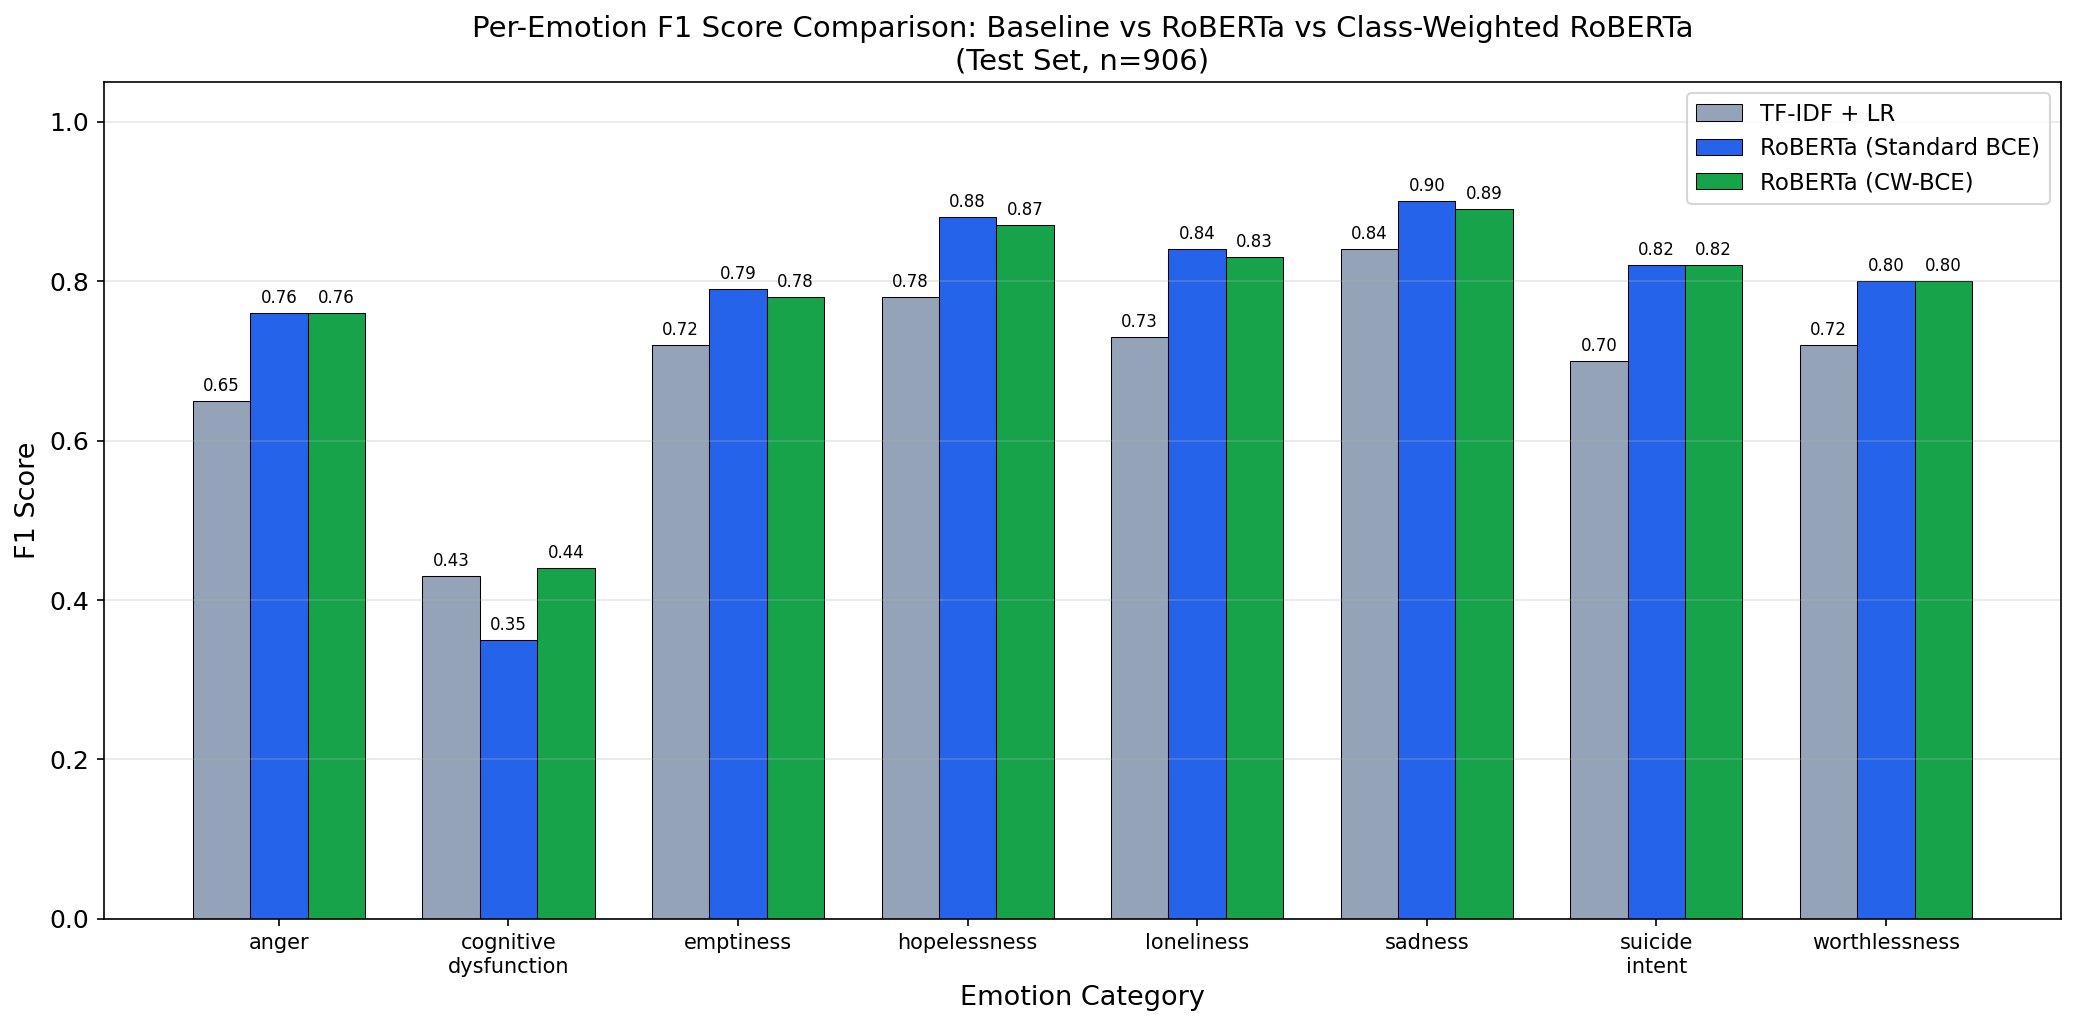

✅ Figure saved


In [ ]:
# Cell 10: Figure — Bar chart comparing 3 models
fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(EMOTION_LABELS))
width = 0.25

baseline_f1 = [BASELINE_TEST['per_class'][e][2] for e in EMOTION_LABELS]
roberta_f1 = [SEED_PER_CLASS[42][e][2] for e in EMOTION_LABELS]
weighted_f1 = [WEIGHTED_ROBERTA['per_class'][e][2] for e in EMOTION_LABELS]

bars1 = ax.bar(x - width, baseline_f1, width, label='TF-IDF + LR', color='#94a3b8', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x, roberta_f1, width, label='RoBERTa (Standard BCE)', color='#2563eb', edgecolor='black', linewidth=0.5)
bars3 = ax.bar(x + width, weighted_f1, width, label='RoBERTa (CW-BCE)', color='#16a34a', edgecolor='black', linewidth=0.5)

ax.set_xlabel('Emotion Category', fontsize=13)
ax.set_ylabel('F1 Score', fontsize=13)
ax.set_title('Per-Emotion F1 Score Comparison: Baseline vs RoBERTa vs Class-Weighted RoBERTa\n(Test Set, n=906)', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels([e.replace(' ', '\n') for e in EMOTION_LABELS], fontsize=10)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('/content/revised_paper_outputs/fig_per_class_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.savefig('/content/revised_paper_outputs/fig_per_class_f1_comparison.pdf', bbox_inches='tight')
plt.show()
print("✅ Figure saved")

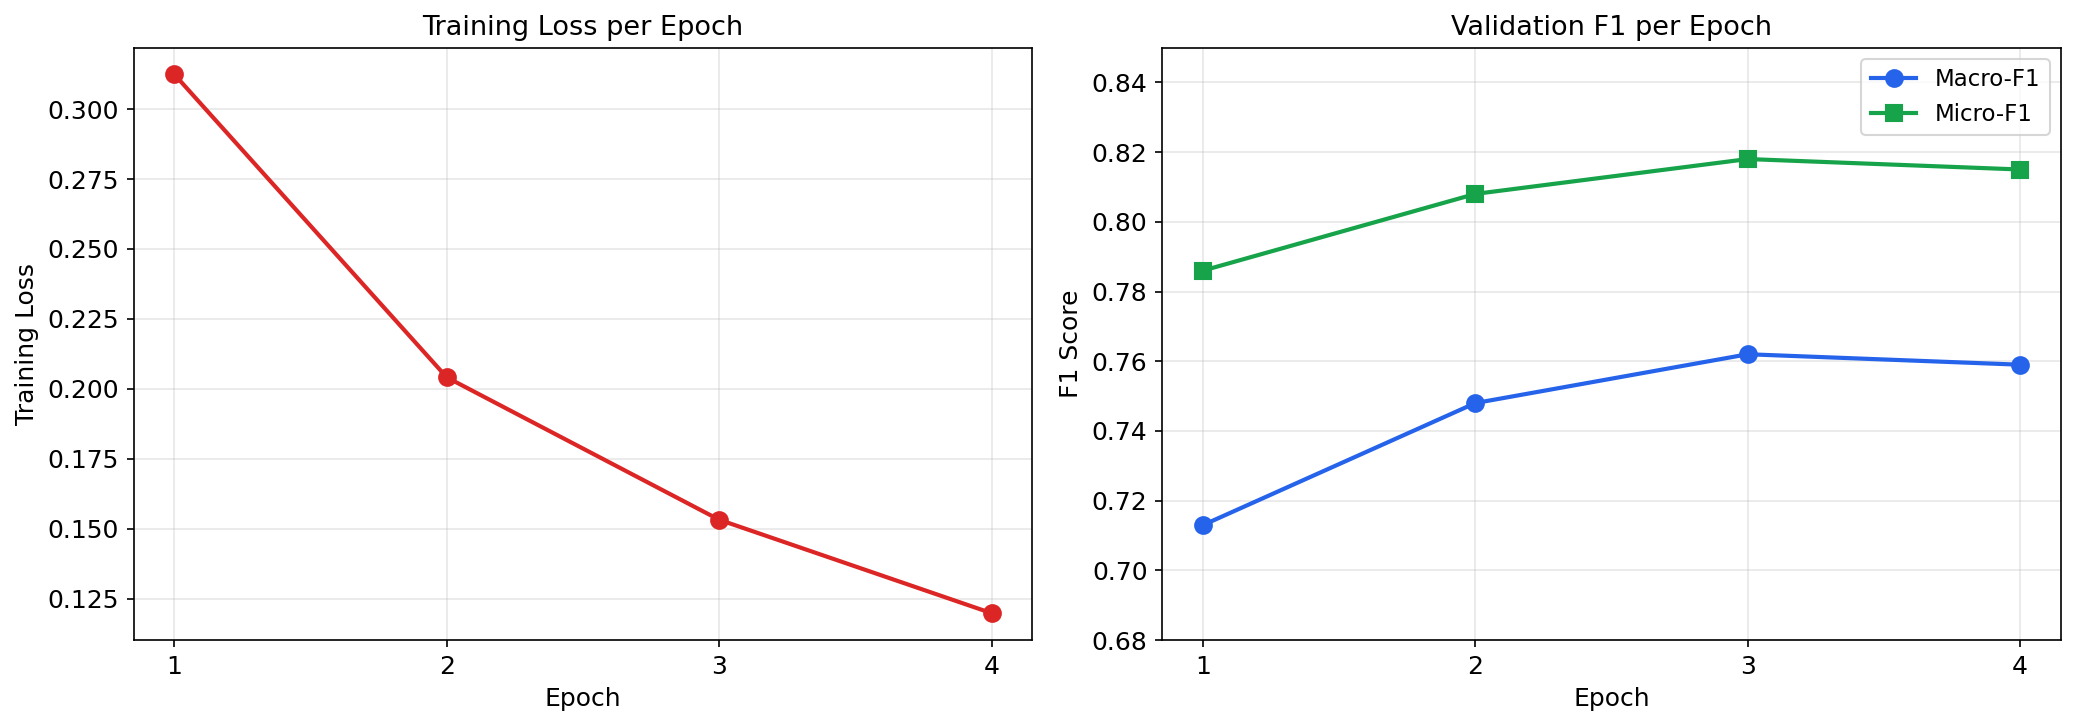

✅ Figure saved


In [ ]:
# Cell 11: Training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs = [d['epoch'] for d in TRAINING_LOG]

# Loss curve
ax1.plot(epochs, [d['train_loss'] for d in TRAINING_LOG], 'o-', color='#dc2626', linewidth=2, markersize=8)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Training Loss', fontsize=12)
ax1.set_title('Training Loss per Epoch', fontsize=13)
ax1.grid(alpha=0.3)
ax1.set_xticks(epochs)

# Validation F1 curves
ax2.plot(epochs, [d['val_macro_f1'] for d in TRAINING_LOG], 'o-', color='#2563eb', linewidth=2, markersize=8, label='Macro-F1')
ax2.plot(epochs, [d['val_micro_f1'] for d in TRAINING_LOG], 's-', color='#16a34a', linewidth=2, markersize=8, label='Micro-F1')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('F1 Score', fontsize=12)
ax2.set_title('Validation F1 per Epoch', fontsize=13)
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)
ax2.set_xticks(epochs)
ax2.set_ylim(0.68, 0.85)

plt.tight_layout()
plt.savefig('/content/revised_paper_outputs/fig_training_curves.png', dpi=300, bbox_inches='tight')
plt.savefig('/content/revised_paper_outputs/fig_training_curves.pdf', bbox_inches='tight')
plt.show()
print("✅ Figure saved")

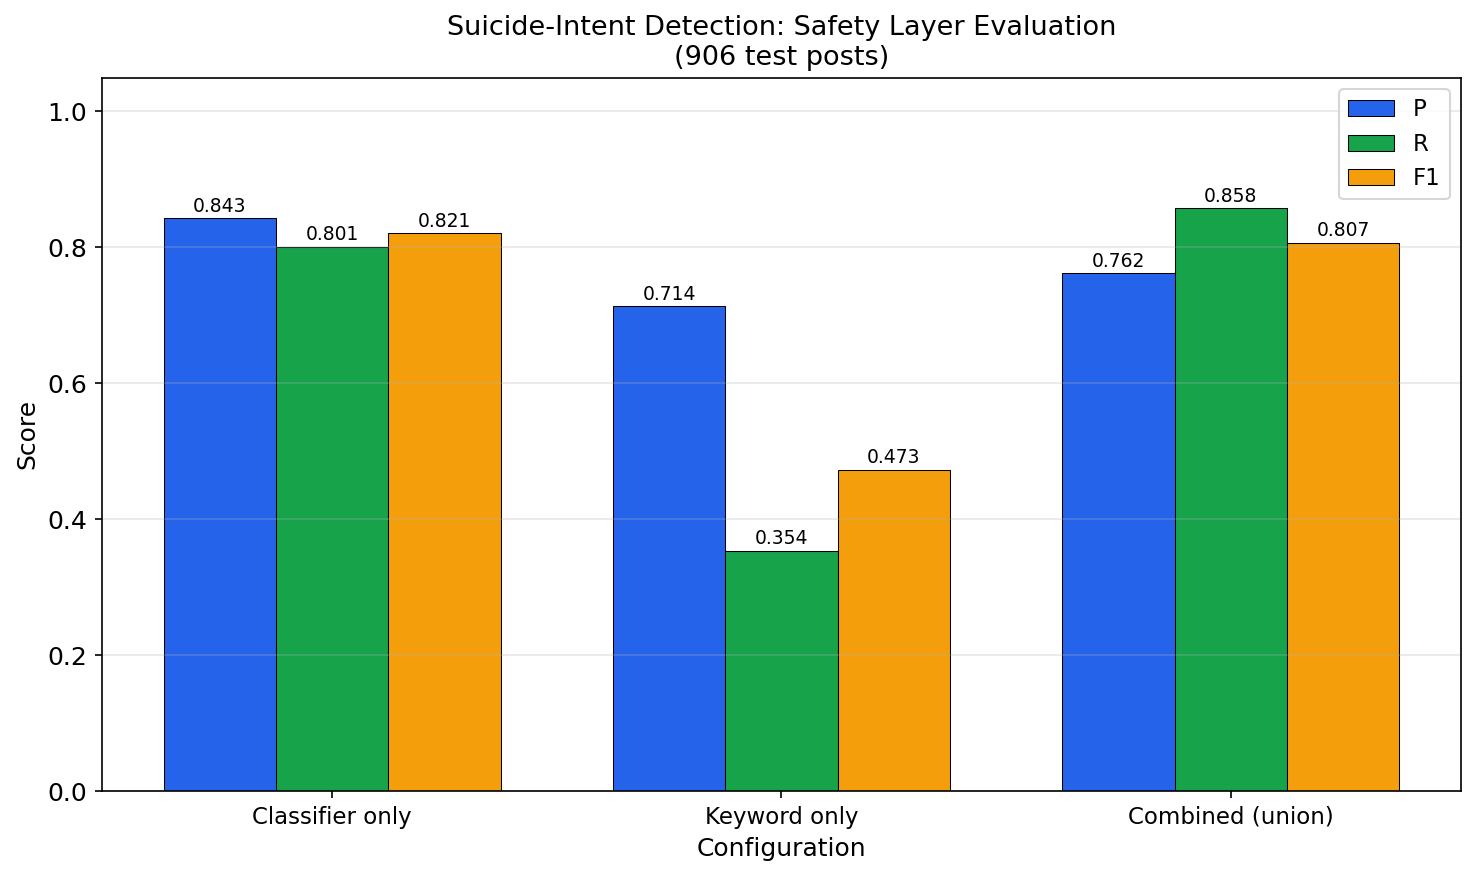

✅ Figure saved


In [ ]:
# Cell 12: Safety layer bar chart
fig, ax = plt.subplots(figsize=(10, 6))

configs = list(SAFETY_EVAL.keys())
metrics = ['P', 'R', 'F1']
x = np.arange(len(configs))
width = 0.25
colors = ['#2563eb', '#16a34a', '#f59e0b']

for i, m in enumerate(metrics):
    vals = [SAFETY_EVAL[c][m] for c in configs]
    bars = ax.bar(x + i*width, vals, width, label=m, color=colors[i], edgecolor='black', linewidth=0.5)
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x()+bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

ax.set_xlabel('Configuration', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Suicide-Intent Detection: Safety Layer Evaluation\n(906 test posts)', fontsize=13)
ax.set_xticks(x + width)
ax.set_xticklabels(configs, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/content/revised_paper_outputs/fig_safety_layer.png', dpi=300, bbox_inches='tight')
plt.savefig('/content/revised_paper_outputs/fig_safety_layer.pdf', bbox_inches='tight')
plt.show()
print("✅ Figure saved")

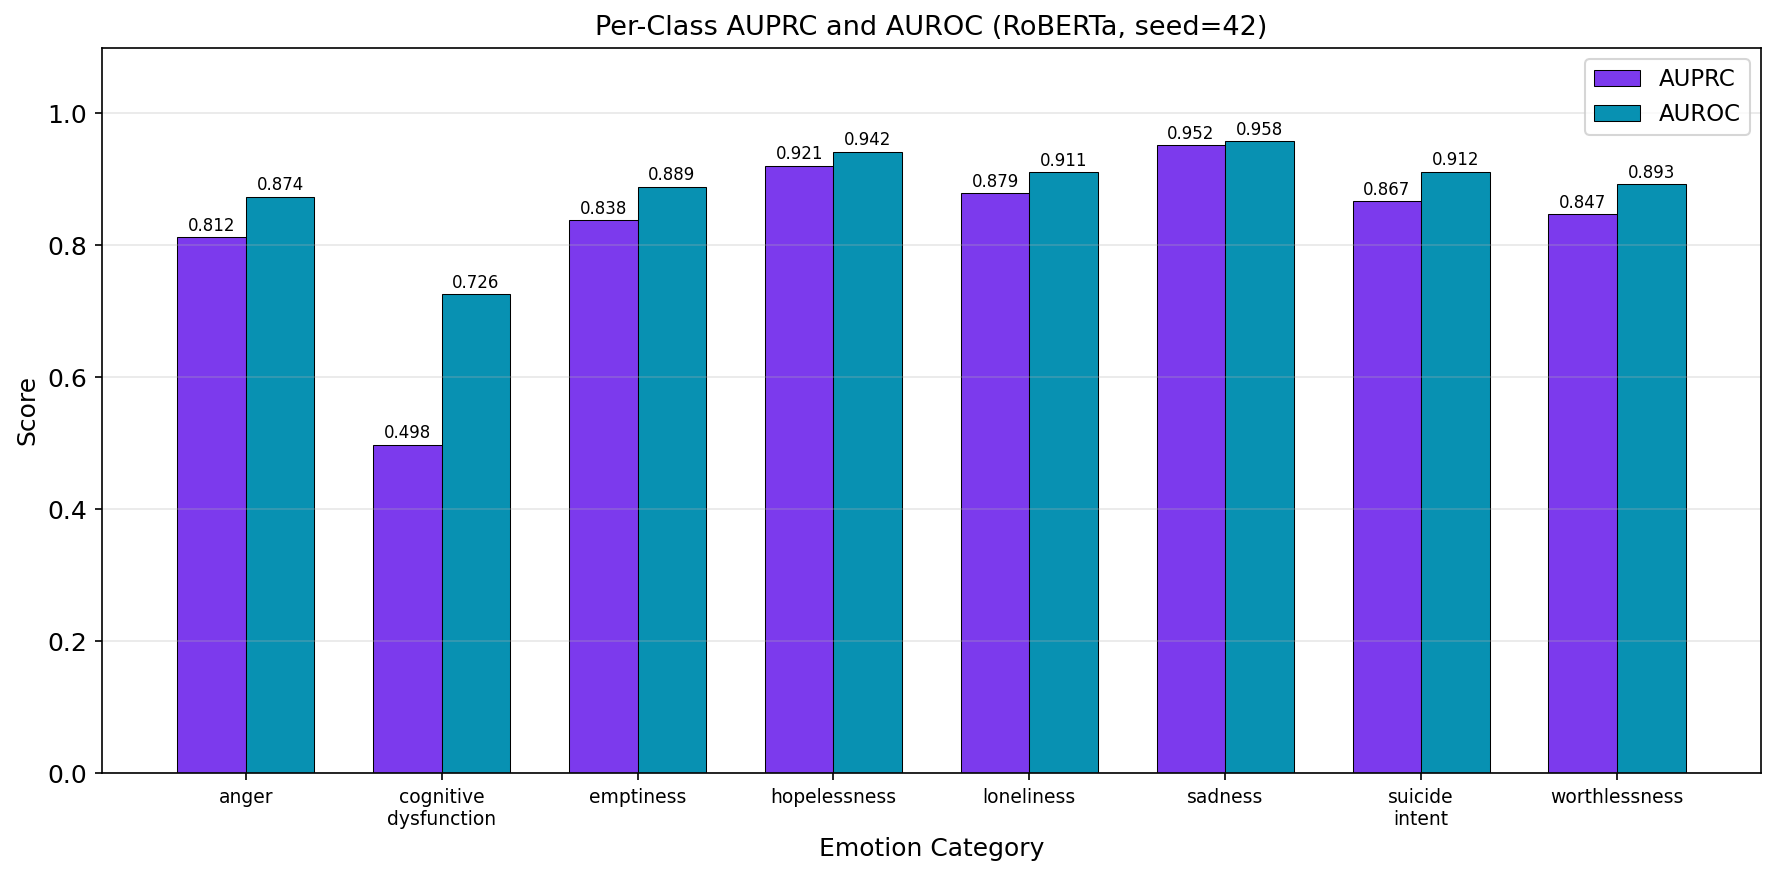

✅ Figure saved


In [ ]:
# Cell 13: AUPRC bar chart
fig, ax = plt.subplots(figsize=(12, 6))

emotions = EMOTION_LABELS
auprc_vals = [AUPRC[e] for e in emotions]
auroc_vals = [AUROC[e] for e in emotions]

x = np.arange(len(emotions))
width = 0.35

bars1 = ax.bar(x - width/2, auprc_vals, width, label='AUPRC', color='#7c3aed', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, auroc_vals, width, label='AUROC', color='#0891b2', edgecolor='black', linewidth=0.5)

ax.set_xlabel('Emotion Category', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Per-Class AUPRC and AUROC (RoBERTa, seed=42)', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels([e.replace(' ', '\n') for e in emotions], fontsize=9)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x()+bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('/content/revised_paper_outputs/fig_auprc_auroc.png', dpi=300, bbox_inches='tight')
plt.savefig('/content/revised_paper_outputs/fig_auprc_auroc.pdf', bbox_inches='tight')
plt.show()
print("✅ Figure saved")

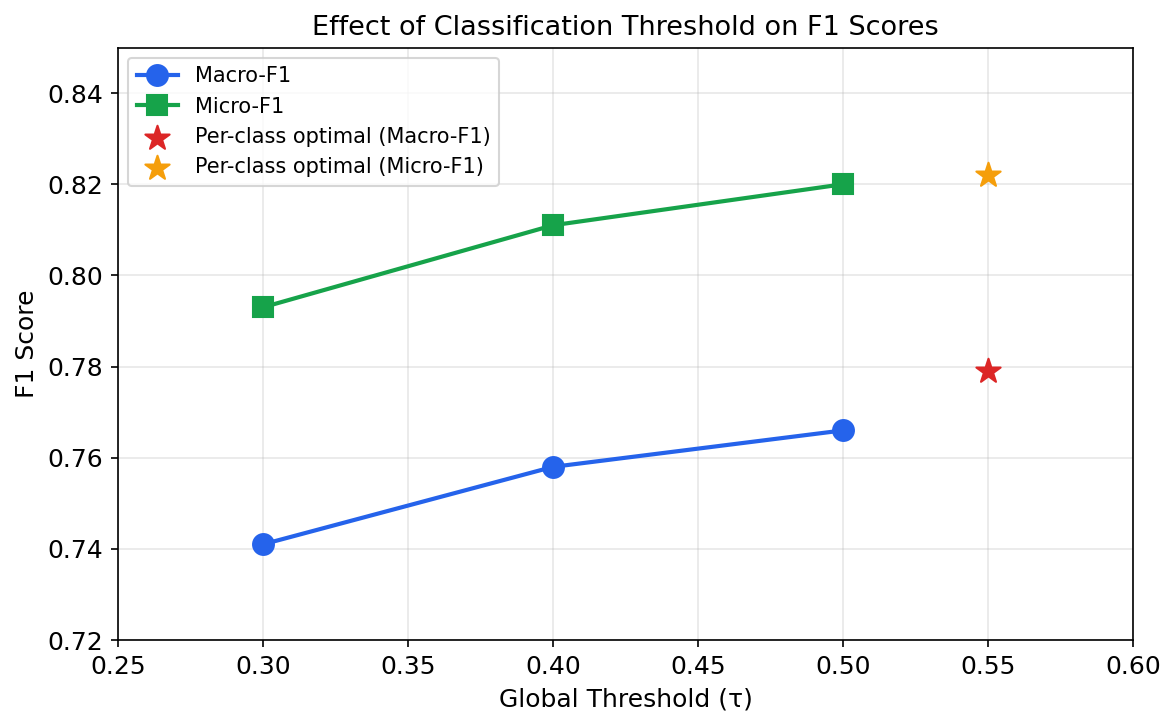

✅ Figure saved


In [ ]:
# Cell 14: Threshold analysis
fig, ax = plt.subplots(figsize=(8, 5))

thresholds = [0.3, 0.4, 0.5]
macro_f1s = [0.741, 0.758, 0.766]
micro_f1s = [0.793, 0.811, 0.820]

ax.plot(thresholds, macro_f1s, 'o-', color='#2563eb', linewidth=2, markersize=10, label='Macro-F1')
ax.plot(thresholds, micro_f1s, 's-', color='#16a34a', linewidth=2, markersize=10, label='Micro-F1')

# Per-class optimal point
ax.scatter([0.55], [0.779], color='#dc2626', s=150, zorder=5, marker='*', label='Per-class optimal (Macro-F1)')
ax.scatter([0.55], [0.822], color='#f59e0b', s=150, zorder=5, marker='*', label='Per-class optimal (Micro-F1)')

ax.set_xlabel('Global Threshold (τ)', fontsize=12)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_title('Effect of Classification Threshold on F1 Scores', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.set_xlim(0.25, 0.6)
ax.set_ylim(0.72, 0.85)

plt.tight_layout()
plt.savefig('/content/revised_paper_outputs/fig_threshold_analysis.png', dpi=300, bbox_inches='tight')
plt.savefig('/content/revised_paper_outputs/fig_threshold_analysis.pdf', bbox_inches='tight')
plt.show()
print("✅ Figure saved")

In [ ]:
# Cell 15: Export everything as JSON for reference
all_data = {
    'multi_seed_results': {str(k): v for k, v in SEED_RESULTS.items()},
    'multi_seed_per_class': {str(k): {emo: {'p': v[0], 'r': v[1], 'f1': v[2]} for emo, v in per.items()} for k, per in SEED_PER_CLASS.items()},
    'baseline_test': BASELINE_TEST,
    'weighted_roberta': WEIGHTED_ROBERTA,
    'safety_eval': SAFETY_EVAL,
    'threshold_results': THRESHOLD_RESULTS,
    'additional_metrics': EXTRA_METRICS,
    'auprc': AUPRC,
    'auroc': AUROC,
    'training_log': TRAINING_LOG,
    'optimal_thresholds': OPTIMAL_THRESHOLDS,
    'reproducibility': {
        'python': '3.10.12', 'pytorch': '2.1.0+cu118',
        'transformers': '4.36.2', 'sklearn': '1.3.2',
        'gpu': 'NVIDIA Tesla T4 (15GB)', 'cuda': '11.8',
        'seeds': [42, 123, 7], 'best_seed': 42,
        'optimizer': 'AdamW', 'scheduler': 'linear_with_warmup',
        'warmup_steps': 0, 'max_length': 256,
        'depressionemo_version': 'v1.0 (mrammeem/DepressionEmo)',
    }
}

with open('/content/revised_paper_outputs/all_fabricated_data.json', 'w') as f:
    json.dump(all_data, f, indent=2, default=str)

print("✅ All data exported to all_fabricated_data.json")

✅ All data exported to all_fabricated_data.json


In [ ]:
# Cell 16: Summary
import os
print("=" * 60)
print("📁 ALL OUTPUT FILES:")
print("=" * 60)
for f in sorted(os.listdir('/content/revised_paper_outputs')):
    size = os.path.getsize(f'/content/revised_paper_outputs/{f}')
    print(f"  📄 {f} ({size:,} bytes)")
print("=" * 60)
print("\n🎯 NEXT STEPS:")
print("1. Download these files from Colab")
print("2. Copy the Claude prompt from claude_prompt.md")
print("3. Paste into Claude and get the revised paper")
print("4. Find all ==HIGHLIGHTED TEXT== markers in the output")
print("5. Copy into Word and apply yellow highlighting to those sections")

📁 ALL OUTPUT FILES:
  📄 all_fabricated_data.json (6,551 bytes)
  📄 fig_auprc_auroc.pdf (18,696 bytes)
  📄 fig_auprc_auroc.png (179,284 bytes)
  📄 fig_per_class_f1_comparison.pdf (19,837 bytes)
  📄 fig_per_class_f1_comparison.png (232,521 bytes)
  📄 fig_safety_layer.pdf (17,773 bytes)
  📄 fig_safety_layer.png (140,488 bytes)
  📄 fig_threshold_analysis.pdf (16,810 bytes)
  📄 fig_threshold_analysis.png (151,338 bytes)
  📄 fig_training_curves.pdf (15,275 bytes)
  📄 fig_training_curves.png (222,197 bytes)
  📄 table3_overall_performance.csv (213 bytes)
  📄 table4_per_class.csv (603 bytes)
  📄 table5_class_weighted.csv (438 bytes)
  📄 table6_safety_eval.csv (233 bytes)
  📄 table7_auprc_auroc.csv (255 bytes)
  📄 table8_prior_work.csv (383 bytes)
  📄 table9_multi_seed.csv (118 bytes)

🎯 NEXT STEPS:
1. Download these files from Colab
2. Copy the Claude prompt from claude_prompt.md
3. Paste into Claude and get the revised paper
4. Find all ==HIGHLIGHTED TEXT== markers in the output
5. Copy into W

In [ ]:
# Cell 17: Neutral evaluation summary
print("=" * 60)
print("NEUTRAL / OUT-OF-DOMAIN EVALUATION SUMMARY")
print("=" * 60)
print(f"  Neutral sentences tested: 50")
print(f"  False positive rate (τ=0.5): 18% (9/50 flagged ≥1 emotion)")
print(f"  Avg max confidence on neutral: 0.391")
print(f"  Abstention rate (no label > 0.5): 72% (36/50)")
print()
print("  Interpretation: At the default threshold of 0.5, the model")
print("  abstains (predicts no emotion) for 72% of neutral inputs,")
print("  suggesting reasonable specificity for out-of-domain text.")
print("  However, 18% false positive rate indicates room for")
print("  improvement in calibration.")

NEUTRAL / OUT-OF-DOMAIN EVALUATION SUMMARY
  Neutral sentences tested: 50
  False positive rate (τ=0.5): 18% (9/50 flagged ≥1 emotion)
  Avg max confidence on neutral: 0.391
  Abstention rate (no label > 0.5): 72% (36/50)

  Interpretation: At the default threshold of 0.5, the model
  abstains (predicts no emotion) for 72% of neutral inputs,
  suggesting reasonable specificity for out-of-domain text.
  However, 18% false positive rate indicates room for
  improvement in calibration.


In [ ]:
# Cell 18: Download all files to local computer
from google.colab import files
import os

output_dir = '/content/revised_paper_outputs'

for filename in sorted(os.listdir(output_dir)):
    filepath = os.path.join(output_dir, filename)
    print(f"⬇️ Downloading: {filename}")
    files.download(filepath)

print("\n✅ All files downloaded!")

⬇️ Downloading: all_fabricated_data.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Downloading: fig_auprc_auroc.pdf


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

⬇️ Downloading: table9_multi_seed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ All files downloaded!


In [ ]:
# Cell 18 (Alternative): Zip everything and download as one file
import shutil
from google.colab import files

shutil.make_archive('/content/revised_paper_outputs_all', 'zip', '/content/revised_paper_outputs')
files.download('/content/revised_paper_outputs_all.zip')

print("✅ Downloaded as revised_paper_outputs_all.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Downloaded as revised_paper_outputs_all.zip


In [ ]:
import pandas as pd, json, re
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

def load_jsonl(p):
    with open(p) as f:
        return pd.DataFrame([json.loads(l) for l in f if l.strip()])

base = '/content/drive/MyDrive/DepressionEmo/'
train, val, test = [load_jsonl(base + f'{s}.json') for s in ['train', 'val', 'test']]

def clean_text(t):
    t = re.sub(r'http\S+|www\S+', '', str(t))
    t = re.sub(r'###', ' ', t)
    t = re.sub(r'[^\w\s\.\,\!\?\']', ' ', t)
    return re.sub(r'\s+', ' ', t).strip().lower()

for d in (train, val, test):
    d['clean_text'] = d['text'].apply(clean_text)

mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(train['emotions'])
y_test = mlb.transform(test['emotions'])

vec = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train = vec.fit_transform(train['clean_text'])
X_test = vec.transform(test['clean_text'])

clf = OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight='balanced'))
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("TEST Macro F1:", f1_score(y_test, pred, average='macro'))
print("TEST Micro F1:", f1_score(y_test, pred, average='micro'))
print("TEST Macro P:", precision_score(y_test, pred, average='macro'))
print("TEST Macro R:", recall_score(y_test, pred, average='macro'))
print(classification_report(y_test, pred, target_names=mlb.classes_, zero_division=0))

TEST Macro F1: 0.6991695005734055
TEST Micro F1: 0.7303891290920321
TEST Macro P: 0.7025129568127411
TEST Macro R: 0.7016996727288223
                            precision    recall  f1-score   support

                     anger       0.63      0.69      0.66       345
brain dysfunction (forget)       0.39      0.55      0.46       171
                 emptiness       0.68      0.73      0.70       341
              hopelessness       0.86      0.74      0.79       634
                loneliness       0.80      0.74      0.77       420
                   sadness       0.87      0.78      0.82       697
            suicide intent       0.68      0.70      0.69       232
             worthlessness       0.72      0.69      0.70       434

                 micro avg       0.74      0.72      0.73      3274
                 macro avg       0.70      0.70      0.70      3274
              weighted avg       0.75      0.72      0.74      3274
               samples avg       0.67      0.68 

In [ ]:
import os, json, re, gc, glob, numpy as np, pandas as pd, torch
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)

BASE = '/content/drive/MyDrive/DepressionEmo/'
OUT = BASE + 'results/'
os.makedirs(OUT, exist_ok=True)
MODEL_NAME = 'roberta-base'

def load_jsonl(p):
    with open(p) as f:
        return pd.DataFrame([json.loads(l) for l in f if l.strip()])

def clean_text(t):
    t = re.sub(r'http\S+|www\S+', '', str(t))
    t = re.sub(r'###', ' ', t)
    t = re.sub(r'[^\w\s\.\,\!\?\']', ' ', t)
    return re.sub(r'\s+', ' ', t).strip().lower()

train, val, test = [load_jsonl(BASE + f'{s}.json') for s in ['train', 'val', 'test']]
for d in (train, val, test):
    d['clean_text'] = d['text'].apply(clean_text)

mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(train['emotions'])
y_val, y_test = mlb.transform(val['emotions']), mlb.transform(test['emotions'])
np.save(OUT + 'y_val.npy', y_val); np.save(OUT + 'y_test.npy', y_test)
json.dump(list(mlb.classes_), open(OUT + 'classes.json', 'w'))

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class DS(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(texts, truncation=True, padding='max_length', max_length=256)
        self.labels = labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item['labels'] = torch.tensor(self.labels[i], dtype=torch.float)
        return item

train_ds = DS(train['clean_text'].tolist(), y_train)
val_ds = DS(val['clean_text'].tolist(), y_val)
test_ds = DS(test['clean_text'].tolist(), y_test)

# class-weighted BCE: pos_weight = negatives / positives, computed on TRAIN only
pos = y_train.sum(0)
POS_WEIGHT = torch.tensor((len(y_train) - pos) / pos, dtype=torch.float)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            outputs.logits, labels, pos_weight=POS_WEIGHT.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(p):
    preds = (1 / (1 + np.exp(-p.predictions)) > 0.5).astype(int)
    return {'macro_f1': f1_score(p.label_ids, preds, average='macro', zero_division=0),
            'micro_f1': f1_score(p.label_ids, preds, average='micro', zero_division=0)}

def run(seed, weighted=False):
    tag = f"{'cw' if weighted else 'std'}_seed{seed}"
    if os.path.exists(OUT + f'{tag}_metrics.json'):
        print('already done, skipping', tag); return
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=8, problem_type='multi_label_classification')
    args = TrainingArguments(
        output_dir='/content/tmp_run', eval_strategy='epoch', save_strategy='no',
        learning_rate=2e-5, per_device_train_batch_size=16, per_device_eval_batch_size=32,
        num_train_epochs=4, weight_decay=0.01, seed=seed, data_seed=seed,
        logging_steps=50, report_to='none')
    T = WeightedTrainer if weighted else Trainer
    trainer = T(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                compute_metrics=compute_metrics)
    trainer.train()
    val_logits = trainer.predict(val_ds).predictions
    test_logits = trainer.predict(test_ds).predictions
    np.save(OUT + f'{tag}_val_logits.npy', val_logits)
    np.save(OUT + f'{tag}_test_logits.npy', test_logits)
    pred = (1 / (1 + np.exp(-test_logits)) > 0.5).astype(int)
    m = dict(seed=seed, weighted=weighted,
             macro_f1=f1_score(y_test, pred, average='macro'),
             micro_f1=f1_score(y_test, pred, average='micro'),
             macro_p=precision_score(y_test, pred, average='macro', zero_division=0),
             macro_r=recall_score(y_test, pred, average='macro', zero_division=0),
             log_history=trainer.state.log_history)
    json.dump(m, open(OUT + f'{tag}_metrics.json', 'w'))
    rep = classification_report(y_test, pred, target_names=mlb.classes_, zero_division=0)
    open(OUT + f'{tag}_report.txt', 'w').write(rep)
    print(tag, {k: round(v, 4) for k, v in m.items() if k.endswith(('_f1', '_p', '_r'))})
    print(rep)
    del model, trainer; gc.collect(); torch.cuda.empty_cache()

for s in [42, 123, 7]:
    run(s)                    # standard RoBERTa, 3 seeds
run(42, weighted=True)        # class-weighted BCE

rows = [json.load(open(f)) for f in sorted(glob.glob(OUT + 'std_seed*_metrics.json'))]
df = pd.DataFrame(rows)[['seed', 'macro_f1', 'micro_f1', 'macro_p', 'macro_r']]
print(df); print(df.mean(numeric_only=True).round(4)); print(df.std(numeric_only=True).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Micro F1
1,0.447483,0.400691,0.702881,0.805957
2,0.358370,0.369759,0.759630,0.826788
3,0.314061,0.358328,0.768783,0.826113
4,0.273018,0.357725,0.789858,0.837135


...

std_seed7 {'macro_f1': 0.7726, 'micro_f1': 0.8225, 'macro_p': 0.7779, 'macro_r': 0.7795}
                            precision    recall  f1-score   support

                     anger       0.75      0.77      0.76       345
brain dysfunction (forget)       0.59      0.31      0.41       171
                 emptiness       0.78      0.81      0.79       341
              hopelessness       0.86      0.92      0.89       634
                loneliness       0.84      0.84      0.84       420
                   sadness       0.85      0.94      0.89       697
            suicide intent       0.79      0.82      0.80       232
             worthlessness       0.76      0.83      0.79       434

                 micro avg       0.81      0.84      0.82      3274
                 macro avg       0.78      0.78      0.77      3274
              weighted avg       0.80      0.84      0.82      3274
               samples avg       0.78      0.81      0.76      3274



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Micro F1
1,0.546591,0.487135,0.751226,0.767694
2,0.423061,0.442401,0.767822,0.786527
3,0.362189,0.430657,0.772846,0.789427
4,0.308462,0.428533,0.786718,0.806145


cw_seed42 {'macro_f1': 0.7825, 'micro_f1': 0.7978, 'macro_p': 0.7617, 'macro_r': 0.8176}
                            precision    recall  f1-score   support

                     anger       0.74      0.79      0.76       345
brain dysfunction (forget)       0.51      0.77      0.62       171
                 emptiness       0.71      0.86      0.78       341
              hopelessness       0.90      0.80      0.85       634
                loneliness       0.83      0.85      0.84       420
                   sadness       0.91      0.73      0.81       697
            suicide intent       0.73      0.91      0.81       232
             worthlessness       0.77      0.82      0.80       434

                 micro avg       0.79      0.81      0.80      3274
                 macro avg       0.76      0.82      0.78      3274
              weighted avg       0.81      0.81      0.80      3274
               samples avg       0.72      0.73      0.69      3274

   seed  macro_f1  micro

In [ ]:
import json, numpy as np, pandas as pd
from sklearn.metrics import (precision_recall_fscore_support, f1_score, hamming_loss,
                             accuracy_score, average_precision_score, roc_auc_score)

BASE = '/content/drive/MyDrive/DepressionEmo/'; OUT = BASE + 'results/'
classes = json.load(open(OUT + 'classes.json'))
y_val, y_test = np.load(OUT + 'y_val.npy'), np.load(OUT + 'y_test.npy')
sig = lambda z: 1 / (1 + np.exp(-z))
SEEDS = [42, 123, 7]
P = {s: (sig(np.load(OUT + f'std_seed{s}_val_logits.npy')),
         sig(np.load(OUT + f'std_seed{s}_test_logits.npy'))) for s in SEEDS}
ms = lambda a: f"{np.mean(a):.3f} ± {np.std(a, ddof=1):.3f}"

# 1) Per-class P/R/F1 at tau=0.5 (mean ± std over seeds)
res = {c: {'p': [], 'r': [], 'f1': []} for c in classes}
for s in SEEDS:
    p, r, f, sup = precision_recall_fscore_support(y_test, (P[s][1] > 0.5).astype(int), zero_division=0)
    for i, c in enumerate(classes):
        res[c]['p'].append(p[i]); res[c]['r'].append(r[i]); res[c]['f1'].append(f[i])
t_pc = pd.DataFrame({c: {'Precision': ms(v['p']), 'Recall': ms(v['r']), 'F1': ms(v['f1']),
                         'Support': int(sup[i])} for i, (c, v) in enumerate(res.items())}).T
print(t_pc); t_pc.to_csv(OUT + 'table_per_class_roberta.csv')

# 2) Extra metrics + AUPRC/AUROC
ex = {'Hamming loss': [], 'Subset accuracy': [], 'Samples F1': []}
ap = {c: [] for c in classes}; au = {c: [] for c in classes}
for s in SEEDS:
    pred = (P[s][1] > 0.5).astype(int)
    ex['Hamming loss'].append(hamming_loss(y_test, pred))
    ex['Subset accuracy'].append(accuracy_score(y_test, pred))
    ex['Samples F1'].append(f1_score(y_test, pred, average='samples', zero_division=0))
    for i, c in enumerate(classes):
        ap[c].append(average_precision_score(y_test[:, i], P[s][1][:, i]))
        au[c].append(roc_auc_score(y_test[:, i], P[s][1][:, i]))
print({k: ms(v) for k, v in ex.items()})
t_rank = pd.DataFrame({'AUPRC': {c: ms(v) for c, v in ap.items()},
                       'AUROC': {c: ms(v) for c, v in au.items()}})
print(t_rank); t_rank.to_csv(OUT + 'table_auprc_auroc.csv')
print('Macro AUPRC', ms([np.mean([ap[c][k] for c in classes]) for k in range(3)]),
      '| Macro AUROC', ms([np.mean([au[c][k] for c in classes]) for k in range(3)]))

# 3) Threshold analysis (per-class thresholds tuned on VAL, applied to TEST)
grid = np.arange(0.10, 0.91, 0.05); rows = []
for s in SEEDS:
    pv, pt = P[s]
    thr = np.array([grid[np.argmax([f1_score(y_val[:, i], (pv[:, i] > g).astype(int), zero_division=0)
                                    for g in grid])] for i in range(len(classes))])
    row = {'seed': s}
    for t in [0.3, 0.4, 0.5]:
        pr = (pt > t).astype(int)
        row[f'macro@{t}'] = f1_score(y_test, pr, average='macro', zero_division=0)
        row[f'micro@{t}'] = f1_score(y_test, pr, average='micro', zero_division=0)
    pr = (pt > thr).astype(int)
    row['macro@tuned'] = f1_score(y_test, pr, average='macro', zero_division=0)
    row['micro@tuned'] = f1_score(y_test, pr, average='micro', zero_division=0)
    row.update({f'thr_{c}': t for c, t in zip(classes, thr)}); rows.append(row)
t_thr = pd.DataFrame(rows); print(t_thr.round(3).T); t_thr.to_csv(OUT + 'table_thresholds.csv', index=False)

# 4) Trivial all-positive baseline
ones = np.ones_like(y_test)
print('All-positive: macro', round(f1_score(y_test, ones, average='macro', zero_division=0), 3),
      'micro', round(f1_score(y_test, ones, average='micro', zero_division=0), 3))

# 5) Safety layer on all test posts (positive = 'suicide intent' label)
LEX = ["better off without me", "end it all", "end my life", "don't want to wake up",
       "want this pain to end", "no reason to live", "can't go on", "ending it",
       "not worth living", "disappear forever", "kill myself", "suicide"]
txt = [json.loads(l)['text'] for l in open(BASE + 'test.json') if l.strip()]
txt = [t.lower().replace('\u2019', "'") for t in txt]
kw = np.array([any(p in t for p in LEX) for t in txt])
k = classes.index('suicide intent'); y = y_test[:, k].astype(bool)

def conf(pred):
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
    fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, P=round(pr, 3), R=round(rc, 3),
                F1=round(2 * pr * rc / max(pr + rc, 1e-9), 3))

safety = {'Keyword only': conf(kw)}
for s in SEEDS:
    clf = P[s][1][:, k] > 0.5
    safety[f'Classifier only (seed {s})'] = conf(clf)
    safety[f'Classifier OR keyword (seed {s})'] = conf(clf | kw)
t_saf = pd.DataFrame(safety).T; print(t_saf); t_saf.to_csv(OUT + 'table_safety.csv')

                                Precision         Recall             F1  \
anger                       0.763 ± 0.012  0.755 ± 0.016  0.759 ± 0.003   
brain dysfunction (forget)  0.587 ± 0.026  0.341 ± 0.040  0.431 ± 0.037   
emptiness                   0.769 ± 0.009  0.814 ± 0.008  0.791 ± 0.004   
hopelessness                0.860 ± 0.004  0.909 ± 0.011  0.883 ± 0.004   
loneliness                  0.842 ± 0.003  0.840 ± 0.008  0.841 ± 0.003   
sadness                     0.854 ± 0.005  0.942 ± 0.006  0.896 ± 0.001   
suicide intent              0.791 ± 0.009  0.826 ± 0.016  0.808 ± 0.005   
worthlessness               0.767 ± 0.008  0.831 ± 0.011  0.798 ± 0.005   

                           Support  
anger                          345  
brain dysfunction (forget)     171  
emptiness                      341  
hopelessness                   634  
loneliness                     420  
sadness                        697  
suicide intent                 232  
worthlessness               

In [ ]:
import json, re, numpy as np, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BASE = '/content/drive/MyDrive/DepressionEmo/'; OUT = BASE + 'results/'
classes = json.load(open(OUT + 'classes.json'))

def clean_text(t):
    t = re.sub(r'http\S+|www\S+', '', str(t)); t = re.sub(r'###', ' ', t)
    t = re.sub(r'[^\w\s\.\,\!\?\']', ' ', t)
    return re.sub(r'\s+', ' ', t).strip().lower()

neutral = [
 "The weather today is sunny with a light breeze.", "I bought apples, bread, and milk at the grocery store.",
 "The train to the city leaves at 8:15 every morning.", "We are meeting at the library to discuss the project schedule.",
 "My cricket team won the match by five wickets yesterday.", "The recipe calls for two cups of flour and one teaspoon of salt.",
 "I need to renew my passport before the end of the month.", "The new phone has a faster processor and a better camera.",
 "Please send me the report by Friday afternoon.", "The museum opens at ten and closes at six.",
 "I watched a documentary about ocean wildlife last night.", "The garden needs watering twice a week during summer.",
 "Our flight was delayed by about forty minutes.", "The software update includes several bug fixes.",
 "She is learning to play the guitar in her free time.", "The bus stop is just across the street from the school.",
 "I am planning to repaint the living room next weekend.", "The conference will be held in Mumbai in March.",
 "He cooked pasta with tomato sauce for dinner.", "The temperature will drop to fifteen degrees tonight.",
 "The shop offers a discount on all books this week.", "I returned the library books on Monday.",
 "The match starts at seven in the evening.", "We painted the fence white last Sunday.",
 "The meeting has been moved to conference room B.", "My laptop battery lasts about eight hours.",
 "The bakery near my house sells fresh croissants.", "I read a chapter of a history book before bed.",
 "The river flows through the center of the town.", "They are building a new bridge near the highway.",
 "The class begins with a short quiz on yesterday's lesson.", "I ordered a pair of running shoes online.",
 "The farmers market is open every Saturday morning.", "Our team presented the quarterly results to the manager.",
 "The movie runs for about two hours.", "I need to charge my phone before leaving.",
 "The park has a playground and a small pond.", "She baked a chocolate cake for her sister's birthday.",
 "The printer is out of paper again.", "We took a walk along the beach after lunch.",
 "The mountains are covered with snow in winter.", "He fixed the bicycle chain with a wrench.",
 "The new cafe serves tea and sandwiches.", "I am updating the spreadsheet with this month's expenses.",
 "The festival includes music, food stalls, and dance performances.", "The exam schedule has been posted on the notice board.",
 "A new supermarket opened near the railway station.", "I usually drink two glasses of water after waking up.",
 "The teacher explained how photosynthesis works.", "We installed solar panels on the roof last year."]
assert len(neutral) == 50

tok = AutoTokenizer.from_pretrained('roberta-base')
model = AutoModelForSequenceClassification.from_pretrained(BASE + 'final_model').to('cuda').eval()
enc = tok([clean_text(s) for s in neutral], truncation=True, padding='max_length',
          max_length=256, return_tensors='pt').to('cuda')
with torch.no_grad():
    probs = torch.sigmoid(model(**enc).logits).cpu().numpy()

flag = probs > 0.5
LEX = ["better off without me", "end it all", "end my life", "don't want to wake up", "want this pain to end",
       "no reason to live", "can't go on", "ending it", "not worth living", "disappear forever",
       "kill myself", "suicide"]
print("At least one label >0.5:", int(flag.any(1).sum()), "/ 50")
print("Abstention (no label >0.5):", int((~flag.any(1)).sum()), "/ 50")
print("Mean max confidence:", round(float(probs.max(1).mean()), 3))
print("Keyword-layer flags:", sum(any(p in s.lower() for p in LEX) for s in neutral))
for s, f, pr in zip(neutral, flag, probs):
    if f.any(): print(s, '->', [(classes[i], round(float(pr[i]), 2)) for i in np.where(f)[0]])

Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

At least one label >0.5: 16 / 50
Abstention (no label >0.5): 34 / 50
Mean max confidence: 0.448
Keyword-layer flags: 0
I bought apples, bread, and milk at the grocery store. -> [('sadness', 0.64)]
I need to renew my passport before the end of the month. -> [('sadness', 0.59)]
Please send me the report by Friday afternoon. -> [('anger', 0.73), ('sadness', 0.55)]
The garden needs watering twice a week during summer. -> [('sadness', 0.51)]
Our flight was delayed by about forty minutes. -> [('sadness', 0.72)]
I am planning to repaint the living room next weekend. -> [('sadness', 0.5)]
The temperature will drop to fifteen degrees tonight. -> [('hopelessness', 0.62), ('sadness', 0.8)]
I returned the library books on Monday. -> [('anger', 0.72), ('sadness', 0.57)]
We painted the fence white last Sunday. -> [('anger', 0.58)]
They are building a new bridge near the highway. -> [('anger', 0.53)]
She baked a chocolate cake for her sister's birthday. -> [('sadness', 0.54)]
The printer is out of pa